# Taswira Analytics: Finding Standard Fetal Planes in Novice Blind Sweeps
## Group 11 Capstone: NatalIA PBF-US1 (version 3.2)

Midwives and nurses with little ultrasound training can acquire **blind sweeps**: free-hand passes of the probe across the abdomen. What they lack is help judging whether a sweep captured a usable, diagnostic frame. This notebook builds and rigorously evaluates a lightweight model that scans every frame of a sweep, finds the five ISUOG standard planes, and decides whether the sweep needs to be repeated.

**Dataset:** [NatalIA PBF-US1](https://zenodo.org/records/14193949) (González et al., 2024; CC BY 4.0). 90 blind-sweep videos (19,407 frames, 700×500) of a 23-week fetal phantom, recorded by 45 volunteers with no ultrasound experience on a Clarius C3 HD3 handheld probe.

| value | class | frames |
|---|---|---|
| 0 | Biparietal (head) | 42 |
| 1 | Abdominal | 63 |
| 2 | Heart | 61 |
| 3 | Spine | 134 |
| 4 | Femur | 46 |
| 5 | No plane | 19,061 |

### What changed from version 2, and why

Version 2 reached a test plane macro-F1 of only **0.12** on a single split with 19 test plane frames, and flagged no sweeps because almost every sweep had at least one false alarm. Version 3 fixes the causes:

| Problem in v2 | Fix in v3 | Section |
|---|---|---|
| Test set of 19 plane frames: results dominated by chance | **5-fold cross-validation grouped by video**; every frame is tested once; bootstrap confidence intervals over videos | 3, 4 |
| Model choice and thresholds could leak test information | **Nested** design: each outer fold tunes on an inner validation split of its training videos only | 3.3 |
| Random negatives were too easy, so near-miss frames became false femur/abdomen calls | Frames within ±3 of a plane are treated as **ambiguous**, and **hard-negative mining** adds the most confusing no-plane frames | 1.5, 3.2 |
| Dark frames (mean brightness 12/255) with black borders, squashed from 700×500 | **Sector crop, contrast stretch, pad to square** before resizing | 1.6 |
| Isolated single-frame spikes | **Temporal smoothing** of probabilities along the sweep | 3.2 |
| Frame-level threshold made every sweep "pass" | **Sweep-level decision**: score = best frame in the sweep, threshold tuned for sweep sensitivity | 3.2, 4.4 |
| Slow end-to-end training limited experiments | Backbone features **cached once**; heads train in seconds, so many configurations × 5 folds are feasible on CPU | 2 |

### What version 3.2 adds (Part 8)

Two questions, using two real-image datasets saved next to this notebook:

1. **Does extra real data help?** About 100 or 400 real hospital images per view from [FETAL_PLANES_DB](https://zenodo.org/record/3904280) (Barcelona) are added to training. Testing stays on the same NatalIA sweeps with the same folds, so the comparison with v3.1 is fair.
2. **Does it work on real African scans?** The final models are tested on the [African fetal planes](https://zenodo.org/records/7540448) set (Malawi, Uganda, Egypt, Ghana, Algeria): head, tummy, thigh bone and chest views.

Neither dataset is Kenyan. Spain teaches anatomy; the African set is the closest available evidence for Kenya.

### What changed in version 3.1, and why

The full version 3 run gave plane macro-F1 0.37 (95% CI 0.30–0.43), plane-present AUC 0.92, sweep hit@5 0.75, but sweep specificity only 0.22. It also showed that the MLP heads took about 4 hours and never beat logistic regression, and that smoothing never helped because planes last only 1–1.2 frames.

| Finding from the v3 run | Change in v3.1 | Section |
|---|---|---|
| MLP heads took ~4 h of the ~5 h run and never won | MLP removed from the grid (`HEADS = ["logreg"]`); the code stays, so it can be re-added | 0.2 |
| Only one regularisation strength was tried | Logistic-regression **C ∈ {0.03, 0.1, 0.3}** compared | 0.2, 3.3 |
| The two backbones each won on some planes | New **"concat"** feature set: EfficientNet-B0 and MobileNetV2 features side by side (no extra feature computation) | 2, 3.3 |
| Smoothing window was 1 in every fold (planes last 1–1.2 frames) | Window grid cut to {1, 3} | 0.2 |
| Sweep score "best frame" passed almost every empty sweep (specificity 0.22) | Sweep score chosen on inner validation from **best frame, mean of top 3, mean of top 5** | 3.2, 4.4 |

18 configurations × 5 folds now run in well under an hour once the caches exist.

### Research questions

| RQ | Question | Section |
|---|---|---|
| RQ1 | Can a lightweight model recognise the five standard planes in novice blind-sweep frames? | 4.1–4.3 |
| RQ2 | At sweep level, does it surface a correct frame for each plane, and correctly flag sweeps with no usable plane? | 4.4–4.5 |
| RQ3 | How robust is it across sweep types and fetal positions? | 5 |
| RQ4 | Does the final model meet size and latency targets for a phone, and what does it look at? | 6 |
| RQ5 | Does adding real hospital images help, and does the model work on real African scans? | 8 |

> **How to run:** keep `NatalIA PBFUS1.zip`, `FETAL_PLANES_ZENODO.zip` and `Zenodo_dataset.tar.xz` (or their extracted folders) next to this notebook and choose *Run All*. The first run unzips the data, preprocesses all frames (about 5 minutes) and computes backbone features (about 10–25 minutes on CPU); both are cached in `cache/`, so later runs take a few minutes.

## Part 0: Environment Setup

In this part we:

1. **Imports (0.1):** load the libraries the notebook uses.
2. **Configuration (0.2):** set every setting in one place and fix the random seeds.
3. **Find the data (0.3):** locate the NatalIA dataset, unzipping it if needed.

**Why:** one settings cell and fixed seeds make the run reproducible. Anyone with the zip file can run the notebook end to end.

### 0.1 Imports
Required packages: `tensorflow scikit-learn pandas seaborn pillow`.

We load every library the notebook needs: Python's built-in tools, NumPy and pandas for data, Matplotlib and seaborn for plots, Pillow for images, TensorFlow/Keras for the neural networks, and scikit-learn for cross-validation and metrics.

**Step 1: Quiet TensorFlow's log messages**

Setting `TF_CPP_MIN_LOG_LEVEL` before TensorFlow is imported hides its long startup messages.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

**Step 2: Import the libraries**

Python's built-in tools (files, JSON, timing, zip files), data tools (NumPy, pandas), plotting (Matplotlib, seaborn), image loading (Pillow), deep learning (TensorFlow/Keras), and scikit-learn for cross-validation, logistic regression, class weights and evaluation metrics.

In [2]:
import re, json, random, pathlib, warnings, time, gc, zipfile
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix, f1_score, recall_score,
                             precision_score, roc_auc_score, average_precision_score,
                             precision_recall_curve, roc_curve)

**Step 3: Tidy the output and check the setup**

Hides warnings, sets the plot style, and prints the TensorFlow version and whether a GPU is available.

In [3]:
warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
sns.set_theme(style="whitegrid")
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.15.0 | GPUs: []


### 0.2 Run Configuration and Reproducibility

Every setting lives here. Changing a preprocessing setting automatically invalidates the cache.

We set up the folders, the class names, and the preprocessing, model and evaluation settings, then fix the random seeds so every run gives the same results.

**Step 1: Seed and folders**

Fixes the random seed (42) and sets up `cache/` (slow-to-compute results, such as preprocessed frames and features) and `outputs/` (the final model and result tables). Both folders are created if missing.

In [4]:
SEED = 42
NOTEBOOK_DIR = pathlib.Path.cwd()
CACHE_DIR = NOTEBOOK_DIR / "cache"
OUT_DIR = NOTEBOOK_DIR / "outputs"
CACHE_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

**Step 2: Class labels**

The six class names. Class 5 (`NO_PLANE`) means no standard plane; classes 0–4 are the planes. `SWEEP_RENAME` gives the two diagonal sweep types clearer names.

In [5]:
CLASS_NAMES = ["biparietal", "abdominal", "heart", "spine", "femur", "no_plane"]
NO_PLANE, PLANE_IDS = 5, [0, 1, 2, 3, 4]
SWEEP_RENAME = {"diagonal": "diagonal 1", "diagonal /": "diagonal 2"}   # labels as stored in metadata.csv

**Step 3: Preprocessing settings**

Image size (224×224), the brightness threshold used to find the ultrasound sector, the contrast-stretch percentiles, and the ±3-frame "ambiguous" buffer around plane frames.

In [6]:
# Preprocessing
IMG_SIZE = 224
CROP_THRESHOLD = 2.0          # mean-intensity threshold that defines the ultrasound sector
CONTRAST_PCT = (1, 99.5)      # per-frame percentile stretch
BUFFER = 3                    # no-plane frames within +/-3 of a plane frame are "ambiguous"

**Step 4: Model settings**

Two backbones × two heads × two negative-sampling strategies = 8 configurations to compare. Also sets the batch size for feature extraction, how many no-plane frames to sample per plane frame, regularisation strength and MLP training length.

In [7]:
# Features and models
FEATURE_BACKBONES = ["efficientnetb0", "mobilenetv2"]   # computed and cached in Part 2
BACKBONES = FEATURE_BACKBONES + ["concat"]              # "concat" = both feature vectors side by side
HEADS = ["logreg"]            # v3.1: the MLP took ~4 h and never beat logistic regression; add "mlp" to re-test
NEGATIVES = ["random", "hard"]
LR_CS = [0.03, 0.1, 0.3]      # logistic-regression regularisation strengths compared (smaller = stronger)
EMB_BATCH = 64
NO_PLANE_RATIO = 10           # random no-plane frames per plane frame in training
HARD_NEG_RATIO = 5            # extra hard negatives per plane frame (hard-negative mining)
LR_C = 0.1                    # default C (used by the MLP option and as a fallback)
MLP_EPOCHS = 40

**Step 5: Evaluation settings**

5 outer folds, a 25% inner validation split, the smoothing windows and frame thresholds to try, the 90% sweep-sensitivity target, 1,000 bootstrap resamples, and the top-*k* values.

In [8]:
# Evaluation
N_FOLDS = 5
INNER_VAL_FRAC = 0.25
SMOOTH_WINDOWS = [1, 3]       # v3.1: v3 chose w = 1 in every fold (planes last only 1-1.2 frames)
FRAME_TAUS = np.round(np.arange(0.05, 0.96, 0.05), 2)
SWEEP_TARGET_SENS = 0.90      # sweeps containing a plane that must pass (not be flagged)
SWEEP_METHODS = ["max", "top3", "top5"]   # sweep score: best frame, or mean of the top 3 / top 5 frames
N_BOOT = 1000
TOP_K = [1, 5]

**Step 6: Fix the random seeds**

`set_seeds()` seeds NumPy, TensorFlow and Python's `random` so every run gives the same results.

In [9]:
def set_seeds(seed=SEED):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    random.seed(seed)

set_seeds()

### 0.3 Locate (and if needed unzip) the dataset next to this notebook

We find the dataset: we search for `resume.csv` next to the notebook, unzip the NatalIA archive if needed, and stop with a helpful message if it still can't be found.

**Step 1: Search for the dataset**

`find_resume()` looks through the notebook's folder (skipping `cache/`) for `resume.csv`, the file that marks the dataset folder.

In [10]:
def find_resume(root):
    return sorted(p for p in root.rglob("resume.csv") if "cache" not in p.parts)

hits = find_resume(NOTEBOOK_DIR)

**Step 2: Unzip it if needed**

If `resume.csv` isn't found, extract any zip file with "natalia" in its name next to the notebook, then search again.

In [11]:
if not hits:
    zips = [z for z in NOTEBOOK_DIR.glob("*.zip") if "natalia" in z.name.lower()]
    print("Zips found:", [z.name for z in zips])
    for z in zips:
        target = NOTEBOOK_DIR / z.stem
        print(f"Extracting {z.name} -> {target} (about a minute) ...")
        with zipfile.ZipFile(z) as zf:
            zf.extractall(target)
    hits = find_resume(NOTEBOOK_DIR)

**Step 3: Stop clearly if it's still missing, otherwise record the folder**

If the dataset still can't be found, list the CSV/JSON files that are there (to help find the problem) and stop with an error. Otherwise save the dataset folder as `DATA_DIR`.

In [12]:
if not hits:
    print("resume.csv not found. CSV/JSON files under this folder:")
    for p in sorted(NOTEBOOK_DIR.rglob("*")):
        if p.suffix.lower() in {".csv", ".json"}:
            print("  ", p.relative_to(NOTEBOOK_DIR))
    raise FileNotFoundError("Put 'NatalIA PBFUS1.zip' or its extracted folder next to this notebook.")
DATA_DIR = hits[0].parent
print("Dataset folder:", DATA_DIR)

Dataset folder: c:\Users\OMokera\Desktop\Moringa\fetal_ultrasound_capstone\NatalIA PBFUS1


## Part 1: Data Understanding and Preparation

In this part we:

1. **Load labels and metadata (1.1):** build one table with a row per frame, its label, its sweep, sweep type and fetal position.
2. **Check class balance (1.2):** count frames per class and how many sweeps contain each plane.
3. **Measure plane runs (1.3):** see how many consecutive frames each plane stays visible.
4. **Design the image clean-up (1.4):** sector crop, contrast stretch and pad-to-square.
5. **Preprocess everything (1.5):** clean all frames once and cache them, check quality, remove duplicate frames with conflicting labels, and mark ambiguous frames next to planes.

**Why:** about 98% of frames show no plane, and the raw frames are dark with black borders. Knowing this shapes how the model is trained and evaluated, and clean, consistent inputs give it a fair chance.

### 1.1 Frame Labels and Sweep Metadata

`resume.csv` has one row per frame; `metadata.csv` one row per sweep with the sweep `protocol` and fetal `position`. Volunteer demographics in `metadata.csv` are **not used**.

We build `frames`, the notebook's main table, with one row per frame. We read the labels, attach each sweep's type and fetal position, and put the frames in the order they were recorded.

**Step 1: Read the frame labels**

Reads `resume.csv` (one row per frame) and stores each frame's file path, label (0–5) and sweep video. Frames whose image file is missing are counted and dropped.

In [13]:
frames = pd.read_csv(DATA_DIR / "resume.csv")
frames.columns = [c.strip() for c in frames.columns]
frames["path"] = [str(DATA_DIR / s / f) for s, f in zip(frames["studie"], frames["file_name"])]
frames["label"] = frames["value"].astype(int)
frames["video"] = frames["studie"].astype(str)
exists = frames["path"].map(os.path.exists)
print(f"Frames listed: {len(frames)} | files found: {exists.sum()} | missing: {(~exists).sum()}")
frames = frames[exists]

Frames listed: 19407 | files found: 19407 | missing: 0


**Step 2: Attach the sweep metadata**

Reads `metadata.csv` and adds each sweep's protocol (`sweep_type`) and `fetal_position`. Study names are normalised (lower case, single spaces) first so the two files match. Missing values become "unknown".

In [14]:
studies = pd.read_csv(DATA_DIR / "metadata.csv")
studies.columns = [c.strip() for c in studies.columns]
norm = lambda s: re.sub(r"\s+", " ", str(s)).strip().lower()
meta = (studies.assign(video_key=studies["Study Name"].map(norm))
        [["video_key", "protocol", "position"]]
        .rename(columns={"protocol": "sweep_type", "position": "fetal_position"})
        .drop_duplicates("video_key"))
frames = frames.assign(video_key=frames["video"].map(norm)).merge(meta, on="video_key", how="left")
for c in ["sweep_type", "fetal_position"]:
    frames[c] = frames[c].fillna("unknown").astype(str).str.strip().str.lower()
frames["sweep_type"] = frames["sweep_type"].replace(SWEEP_RENAME)
frames["fetal_position"] = frames["fetal_position"].str.upper()

**Step 3: Put frames in sweep order**

Takes the frame number from the file name (`cineframe_<n>`), sorts frames within each sweep, and stores their order as `pos` (0, 1, 2, …). Then prints how many sweeps there are of each sweep type and fetal position.

In [15]:
# Frame order within each sweep, from the file name (cineframe_<n>_...)
frames["frame_no"] = pd.to_numeric(frames["file_name"].str.extract(r"cineframe_(\d+)", expand=False),
                                   errors="coerce")
frames = frames.sort_values(["video", "frame_no", "file_name"]).reset_index(drop=True)
frames["pos"] = frames.groupby("video").cumcount()
print("Sweep types:", frames.groupby("sweep_type")["video"].nunique().to_dict())
print("Fetal positions:", frames.groupby("fetal_position")["video"].nunique().to_dict())

Sweep types: {'diagonal 1': 20, 'diagonal 2': 22, 'horizontal': 27, 'vertical': 21}
Fetal positions: {'OA': 15, 'OP': 34, 'SA': 15, 'SP': 26}


### 1.2 Class Balance and Plane Coverage

We check how unbalanced the data is: how many frames each class has, how many sweeps contain each plane, and how long the sweeps are. We also create `per_video`, a one-row-per-sweep summary used throughout the notebook.

**Step 1: Summarise sweeps and classes**

`per_video` has one row per sweep: number of frames, number of plane frames, sweep type, fetal position, and `has_plane` (whether it contains any standard plane). Also counts frames per class and how many sweeps contain each plane.

In [16]:
per_video = frames.groupby("video").agg(n_frames=("label", "size"),
                                        plane_frames=("label", lambda s: (s != NO_PLANE).sum()),
                                        sweep_type=("sweep_type", "first"),
                                        fetal_position=("fetal_position", "first"))
per_video["has_plane"] = per_video["plane_frames"] > 0
counts = frames["label"].value_counts().reindex(range(6), fill_value=0)
coverage = frames[frames["label"] != NO_PLANE].groupby("label")["video"].nunique().reindex(range(6), fill_value=0)

**Step 2: Plot and print the summary**

Three charts: plane frames per class (the title shows the share of "no plane" frames), sweeps containing each plane, and a histogram of sweep lengths. Then prints the number of plane-free sweeps and a sweep type × fetal position table.

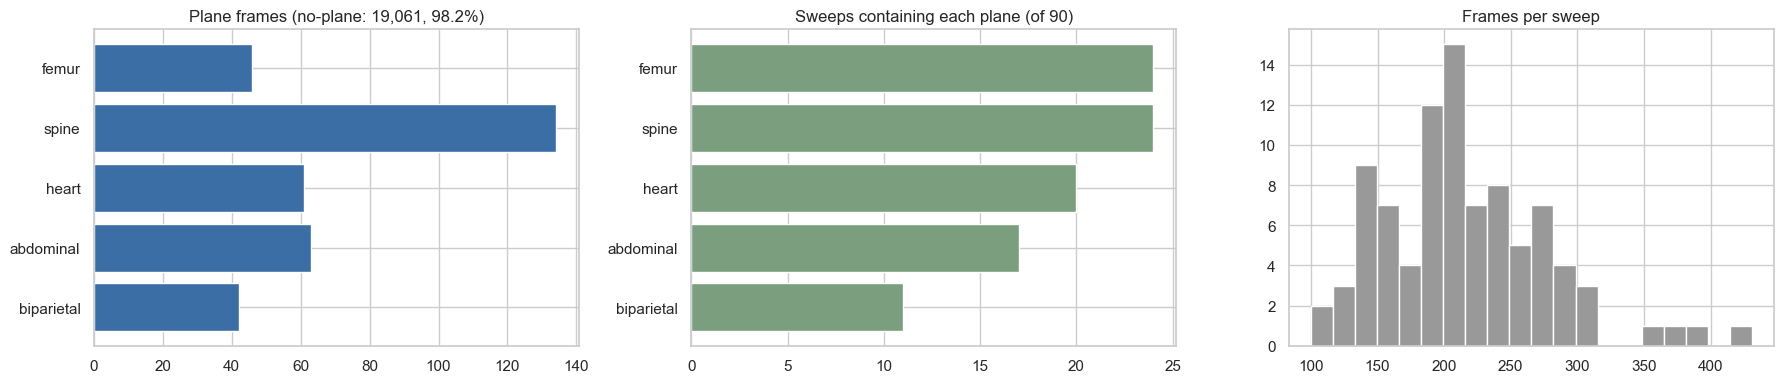

Sweeps with no standard plane: 36 of 90


fetal_position,OA,OP,SA,SP,All
sweep_type,,,,,
diagonal 1,3,8,3,6,20
diagonal 2,3,9,4,6,22
horizontal,5,9,5,8,27
vertical,4,8,3,6,21
All,15,34,15,26,90


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].barh(CLASS_NAMES[:5], counts.values[:5], color="#3b6ea5")
axes[0].set_title(f"Plane frames (no-plane: {counts[NO_PLANE]:,}, {100*counts[NO_PLANE]/counts.sum():.1f}%)")
axes[1].barh(CLASS_NAMES[:5], coverage.values[:5], color="#7a9e7e")
axes[1].set_title(f"Sweeps containing each plane (of {len(per_video)})")
axes[2].hist(per_video["n_frames"], bins=20, color="#999")
axes[2].set_title("Frames per sweep")
plt.tight_layout()
plt.show()
print(f"Sweeps with no standard plane: {(~per_video['has_plane']).sum()} of {len(per_video)}")
display(pd.crosstab(per_video["sweep_type"], per_video["fetal_position"], margins=True))

### 1.3 Where Do Planes Occur Within a Sweep?

Plane frames come in short runs. Neighbouring "no plane" frames are visually almost identical, which is why they are treated as ambiguous in training (1.5).

We walk through each sweep frame by frame and find runs of consecutive frames with the same label. The table shows how many runs each plane has and how long they last; short runs mean a plane is visible only for a moment.

In [18]:
runs = []
for vid, g in frames.groupby("video"):
    lab = g["label"].values
    start = 0
    for i in range(1, len(lab) + 1):
        if i == len(lab) or lab[i] != lab[start]:
            if lab[start] != NO_PLANE:
                runs.append({"plane": CLASS_NAMES[lab[start]], "run_length": i - start})
            start = i
runs = pd.DataFrame(runs)
display(runs.groupby("plane")["run_length"].describe()[["count", "mean", "min", "max"]].round(1))

,count,mean,min,max
plane,,,,
abdominal,54.0,1.2,1.0,3.0
biparietal,37.0,1.1,1.0,2.0
femur,46.0,1.0,1.0,1.0
heart,54.0,1.1,1.0,2.0
spine,117.0,1.1,1.0,4.0


### 1.4 Sector Crop, Contrast Stretch and Pad-to-square

The scanner draws the image in a fan-shaped sector on a black background. We find that sector once from the mean of 300 frames (all frames come from the same device and depth), crop to it, stretch each frame's contrast between its 1st and 99.5th percentile, pad to a square and resize. This keeps anatomy undistorted.

We find the ultrasound sector from the average of 300 frames, define `preprocess()` (the clean-up applied to every frame), and show raw and cleaned frames side by side.

**Step 1: Find the ultrasound sector**

Averages 300 random frames. Pixels brighter than `CROP_THRESHOLD` in the average form the fan-shaped sector, and the box around it (plus a small margin) becomes `CROP`. One box works for all frames because they come from the same device and depth.

In [19]:
rng0 = np.random.default_rng(SEED)
sample_paths = rng0.choice(frames["path"].values, size=min(300, len(frames)), replace=False)
mean_img = np.mean([np.asarray(Image.open(p).convert("L"), dtype=np.float32) for p in sample_paths], axis=0)
mask = mean_img > CROP_THRESHOLD
rows, cols = np.where(mask.any(1))[0], np.where(mask.any(0))[0]
CROP = (int(max(cols[0] - 4, 0)), int(max(rows[0] - 4, 0)),
        int(min(cols[-1] + 5, mean_img.shape[1])), int(min(rows[-1] + 5, mean_img.shape[0])))
print(f"Raw size {mean_img.shape[1]}x{mean_img.shape[0]} -> crop box (left, top, right, bottom) {CROP}")

Raw size 700x500 -> crop box (left, top, right, bottom) (50, 28, 657, 467)


**Step 2: Define the clean-up for one frame**

`preprocess()` crops to `CROP`, stretches contrast so the 1st–99.5th percentile range fills 0–255, pads with black to a square (so anatomy isn't squashed), and resizes to 224×224.

In [20]:
def preprocess(img_gray):
    a = np.asarray(img_gray.crop(CROP), dtype=np.float32)
    lo, hi = np.percentile(a, CONTRAST_PCT)
    a = np.clip((a - lo) / max(hi - lo, 1e-6) * 255.0, 0, 255).astype(np.uint8)
    h, w = a.shape
    s = max(h, w)
    sq = np.zeros((s, s), np.uint8)
    sq[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = a
    return np.asarray(Image.fromarray(sq).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))

**Step 3: Show it working**

Plots the mean image, the sector mask with the crop box in red, and three plane frames before and after preprocessing.

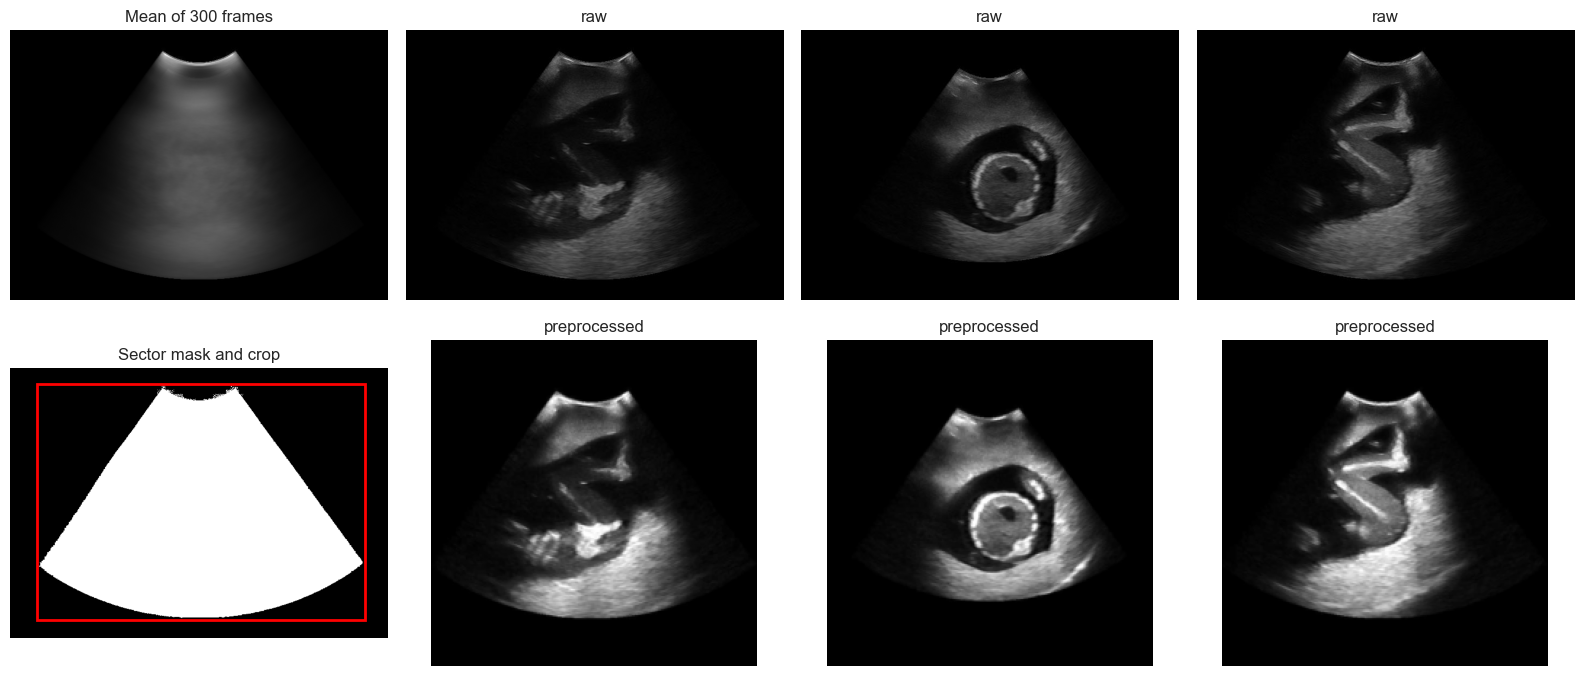

In [21]:
demo = frames[frames["label"] != NO_PLANE].sample(3, random_state=SEED)["path"].tolist()
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes[0, 0].imshow(mean_img, cmap="gray"); axes[0, 0].set_title("Mean of 300 frames")
axes[1, 0].imshow(mask, cmap="gray"); axes[1, 0].set_title("Sector mask and crop")
x0, y0, x1, y1 = CROP
axes[1, 0].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="red", lw=2))
for k, p in enumerate(demo, start=1):
    im = Image.open(p).convert("L")
    axes[0, k].imshow(im, cmap="gray", vmin=0, vmax=255); axes[0, k].set_title("raw")
    axes[1, k].imshow(preprocess(im), cmap="gray", vmin=0, vmax=255); axes[1, k].set_title("preprocessed")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

### 1.5 Preprocess All Frames Once (cached), Audit Quality, Remove Conflicting Duplicates

One pass reads every JPEG, records quality statistics and a perceptual hash, and stores the preprocessed frame in a memory-mapped array (`cache/`, about 1 GB). Exact duplicate frames carrying **different** labels are label noise and are removed.

We preprocess every frame once and cache the result, so later runs skip this slow step. Along the way we record quality statistics, remove duplicate frames that carry conflicting labels, and mark the ambiguous no-plane frames next to each plane.

**Step 1: Check for a usable cache**

`cfg_key` records the preprocessing settings. The saved frames are reused only if these settings and the frame count are unchanged.

In [22]:
cfg_key = f"{IMG_SIZE}_{CROP}_{CONTRAST_PCT}"
img_path, stats_path, key_path = (CACHE_DIR / "frames.npy", CACHE_DIR / "frame_stats.csv",
                                  CACHE_DIR / "frames_key.json")
cache_ok = (img_path.exists() and stats_path.exists() and key_path.exists()
            and json.loads(key_path.read_text()) == {"key": cfg_key, "n": len(frames)})

**Step 2: Preprocess and save every frame (first run only)**

Reads each JPEG once. It records brightness, contrast and a **difference hash** (`dhash`, a tiny fingerprint that is identical for duplicate images), and writes the preprocessed frame to `cache/frames.npy`. Progress prints every 2,000 frames.

In [23]:
if not cache_ok:
    t0 = time.time()
    store = np.lib.format.open_memmap(img_path, mode="w+", dtype=np.uint8, shape=(len(frames), IMG_SIZE, IMG_SIZE))
    rows_ = []
    for i, p in enumerate(frames["path"]):
        g = Image.open(p).convert("L")
        a = np.asarray(g, dtype=np.float32)
        d = np.asarray(g.resize((17, 16)), dtype=np.int16)
        rows_.append({"brightness": a.mean(), "contrast": a.std(),
                      "dhash": np.packbits((d[:, 1:] > d[:, :-1]).ravel()).tobytes().hex()})
        store[i] = preprocess(g)
        if (i + 1) % 2000 == 0:
            print(f"  {i + 1}/{len(frames)} frames ({time.time() - t0:.0f}s)")
    store.flush()
    del store
    pd.DataFrame(rows_).to_csv(stats_path, index=False)
    key_path.write_text(json.dumps({"key": cfg_key, "n": len(frames)}))
    print(f"Preprocessed {len(frames)} frames in {time.time() - t0:.0f}s")
else:
    print("Using cached preprocessed frames.")

Using cached preprocessed frames.


**Step 3: Load the cache and the quality statistics**

`IMAGES` opens the saved frames as a memory map, so frames are read from disk when needed instead of all loading into memory. `row` links each frame to its place in `IMAGES`. Shows median brightness and contrast per class.

In [24]:
IMAGES = np.load(img_path, mmap_mode="r")
frames = pd.concat([frames, pd.read_csv(stats_path)], axis=1)
frames["row"] = np.arange(len(frames))           # row in IMAGES and in the feature caches

display(frames.assign(cls=frames["label"].map(dict(enumerate(CLASS_NAMES))))
        .groupby("cls")[["brightness", "contrast"]].median().round(1))

,brightness,contrast
cls,,
abdominal,13.5,25.9
biparietal,15.6,26.5
femur,13.2,24.8
heart,14.5,26.3
no_plane,11.9,23.2
spine,15.0,27.2


**Step 4: Remove duplicates with conflicting labels**

Identical frames (same `dhash`) that carry **different** labels are label noise, so they are removed. `pos` is then recomputed.

In [25]:
conflict = frames.groupby("dhash")["label"].transform("nunique") > 1
print(f"Frames in duplicate groups with conflicting labels (removed): {conflict.sum()}")
frames = frames[~conflict].reset_index(drop=True)
frames["pos"] = frames.groupby("video").cumcount()

Frames in duplicate groups with conflicting labels (removed): 2


**Step 5: Mark ambiguous frames**

No-plane frames within ±3 positions of a plane frame look almost identical to it. They are marked `near_plane` and never used as negative training examples. `Y` holds every frame's final label.

In [26]:
# Ambiguous no-plane frames next to a plane run
near = np.zeros(len(frames), bool)
for vid, idx in frames.groupby("video").indices.items():
    g = frames.iloc[idx]
    pp = g.loc[g["label"] != NO_PLANE, "pos"].values
    if len(pp):
        dist = np.abs(g["pos"].values[:, None] - pp[None, :]).min(1)
        near[idx] = (dist <= BUFFER) & (g["label"].values == NO_PLANE)
frames["near_plane"] = near
print(f"Ambiguous no-plane frames (within ±{BUFFER} of a plane): {near.sum()}")
Y = frames["label"].values

Ambiguous no-plane frames (within ±3 of a plane): 1422


## Part 2: Backbone Features (computed once, cached)

Each preprocessed frame passes once through an ImageNet-pretrained backbone (EfficientNet-B0, MobileNetV2) with global average pooling. The resulting feature vectors are cached, so every model in Part 3 trains in seconds. This trades end-to-end fine-tuning (which gave almost no gain in v2: 0.15 → 0.16 validation macro-F1) for proper cross-validation, mining and ablations.

In this part we:

1. **Build the backbones:** load EfficientNet-B0 and MobileNetV2, pretrained on ImageNet, without their classification layers.
2. **Save the backbone weights:** so the final model in Part 6 uses exactly the same weights.
3. **Compute features once:** pass every frame through each backbone and cache the resulting feature vectors.

**Why:** with features computed once, each model in Part 3 trains in seconds instead of hours. That makes it practical to cross-validate 8 configurations on a CPU.

**Step 1: Build a pretrained backbone**

Loads EfficientNet-B0 or MobileNetV2 with ImageNet weights, removes the classification layer and averages the last feature maps, so each image becomes one fixed-length vector. MobileNetV2 needs pixels rescaled to −1…1; EfficientNet does this itself.

In [27]:
def make_backbone(name):
    inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    if name == "efficientnetb0":
        base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", pooling="avg",
                                                 input_shape=(IMG_SIZE, IMG_SIZE, 3))
        x = inp                                   # EfficientNet rescales 0-255 internally
    elif name == "mobilenetv2":
        base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", pooling="avg",
                                              input_shape=(IMG_SIZE, IMG_SIZE, 3))
        x = layers.Rescaling(1 / 127.5, offset=-1)(inp)
    else:
        raise ValueError(name)
    return keras.Model(inp, base(x, training=False), name=f"{name}_features")

**Step 2: Save and reload the backbone's weights**

Saves the weights the first time and reloads them afterwards, so the final model in Part 6 matches the cached features exactly.

In [28]:
def get_backbone(name):
    # The exact backbone used for the cached features is saved, so the packaged model in Part 6 matches it.
    # Weights only: reloading a whole EfficientNet .keras file fails on some TF 2.13-2.15 versions.
    path = CACHE_DIR / f"backbone_{name}_{IMG_SIZE}.weights.h5"
    model = make_backbone(name)
    if path.exists():
        model.load_weights(path)
    else:
        model.save_weights(path)
    return model

**Step 3: Compute features, or load them from the cache**

Returns saved features if they exist (the file name includes a hash of the preprocessing settings). Otherwise it feeds all frames through the backbone in batches of 64, copying the grey channel three times because the networks expect colour. It then saves the result and frees memory.

In [29]:
def features(name):
    import hashlib
    path = CACHE_DIR / f"feat_{name}_{hashlib.md5(cfg_key.encode()).hexdigest()[:8]}.npy"
    if path.exists() and (CACHE_DIR / f"backbone_{name}_{IMG_SIZE}.weights.h5").exists():
        F = np.load(path)
        if len(F) == len(IMAGES):
            return F
    model = get_backbone(name)
    F = np.zeros((len(IMAGES), model.output_shape[-1]), np.float16)
    t0 = time.time()
    for s in range(0, len(IMAGES), EMB_BATCH):
        x = np.repeat(np.asarray(IMAGES[s:s + EMB_BATCH])[..., None], 3, axis=-1).astype(np.float32)
        F[s:s + EMB_BATCH] = model.predict(x, verbose=0)
        if (s // EMB_BATCH) % 50 == 0:
            print(f"  {name}: {s}/{len(IMAGES)} ({time.time() - t0:.0f}s)")
    np.save(path, F)
    print(f"{name}: {F.shape} in {time.time() - t0:.0f}s")
    del model
    keras.backend.clear_session()
    return F

**Step 4: Run it for both backbones**

Stores each backbone's features in `FEATS`, row-aligned with `frames` (after duplicate removal).

In [30]:
FEATS = {}
for b in FEATURE_BACKBONES:
    FEATS[b] = features(b)[frames["row"].values].astype(np.float32)   # aligned with `frames`
    print(b, FEATS[b].shape)
FEATS["concat"] = np.hstack([FEATS[b] for b in FEATURE_BACKBONES])  # no extra computation needed
print("concat", FEATS["concat"].shape)

efficientnetb0 (19405, 1280)
mobilenetv2 (19405, 1280)
concat (19405, 2560)


## Part 3: Modelling with Nested, Video-grouped Cross-validation

In this part we:

1. **Outer folds (3.1):** split the sweeps into 5 folds so every frame is tested once.
2. **Building blocks (3.2):** define sampling, the two model heads, hard-negative mining, smoothing, frame and sweep decisions, and threshold tuning.
3. **Nested cross-validation (3.3):** for each of the 8 configurations and 5 folds, tune on inner validation sweeps, then predict the untouched test fold.
4. **Compare and select (3.4):** score every configuration and pick the best using inner-validation scores only.
5. **Ablations (3.5):** measure what each fix (hard negatives, smoothing, backbone) contributes.

**Why:** with only 346 plane frames, a single train/test split gives unreliable numbers. Grouping by sweep stops the model being tested on a sweep it trained on, and nesting keeps all tuning away from the test data.

### 3.1 Outer Folds

Five folds, grouped by sweep video and stratified by label. Every frame is in exactly one test fold.

We split the sweeps into 5 folds, keeping every sweep inside a single fold and giving each fold a similar mix of classes, then check that no sweep was split.

**Step 1: Define the fold split**

`StratifiedGroupKFold` keeps all frames of a sweep in the same fold (**grouped**, so the model is never tested on a sweep it trained on), and gives each fold a similar mix of classes (**stratified**).

In [31]:
def grouped_folds(df, k, seed=SEED):
    k = min(k, df["video"].nunique())
    sgkf = StratifiedGroupKFold(n_splits=k, shuffle=True, random_state=seed)
    fold = np.full(len(df), -1)
    for i, (_, te) in enumerate(sgkf.split(df, df["label"], df["video"])):
        fold[te] = i
    return fold

**Step 2: Assign folds and check them**

Gives every frame a fold number and shows frames per class per fold, plus the number of sweeps and plane-containing sweeps per fold. The `assert` checks that no sweep is split across two folds.

In [32]:
frames["fold"] = grouped_folds(frames, N_FOLDS)
fold_table = pd.crosstab(frames["label"].map(dict(enumerate(CLASS_NAMES))), frames["fold"]).reindex(CLASS_NAMES)
fold_table.loc["sweeps"] = frames.groupby("fold")["video"].nunique()
fold_table.loc["sweeps with a plane"] = frames.groupby("fold").apply(
    lambda g: g.groupby("video")["label"].apply(lambda s: (s != NO_PLANE).any()).sum())
display(fold_table)
assert frames.groupby("video")["fold"].nunique().max() == 1, "a video spans two folds"
print("Each video sits in exactly one fold.")

fold,0,1,2,3,4
label,,,,,
biparietal,13,3,10,2,14
abdominal,13,8,12,10,20
heart,8,5,18,12,18
spine,30,7,14,23,59
femur,20,2,6,6,12
no_plane,3996,3380,3737,4040,3907
sweeps,18,18,18,18,18
sweeps with a plane,10,6,13,11,14


Each video sits in exactly one fold.


### 3.2 Building Blocks: Sampling, Heads, Hard-negative Mining, Smoothing, Decisions

- **Sampling:** every plane frame, plus `NO_PLANE_RATIO` random no-plane frames per plane frame. Ambiguous frames (±3 of a plane) are never used as negatives.
- **Heads:** multinomial logistic regression on standardised features with balanced class weights, at three regularisation strengths (a small MLP is still available but no longer in the grid).
- **Hard-negative mining:** after a first fit, the no-plane training frames the model rates most plane-like are added and the head is refitted.
- **Smoothing:** class probabilities are averaged over a centred window of *w* frames along each sweep.
- **Frame decision:** a frame is a plane if P(plane) = 1 − P(no plane) ≥ τ; its type is the most likely plane.
- **Sweep decision:** sweep score = the best frame's P(plane), or the mean of the top 3 or top 5 frames (chosen on inner validation); sweeps below τ_sweep are **flagged for a rescan**.

We define the functions the rest of the modelling is built from: which frames to train on, the two model heads, hard-negative mining, smoothing, frame and sweep decisions, and threshold tuning. Nothing is trained yet.

**Step 1: List the 8 configurations**

`Config` describes one combination of backbone, head and negative-sampling strategy; `CONFIGS` holds all 8.

In [33]:
@dataclass(frozen=True)
class Config:
    backbone: str
    head: str
    negatives: str
    C: float = LR_C
    def name(self):
        reg = f" | C={self.C}" if self.head == "logreg" else ""
        return f"{self.backbone} | {self.head}{reg} | {self.negatives} negatives"

CONFIGS = [Config(b, h, n, C) for b in BACKBONES for h in HEADS for n in NEGATIVES
           for C in (LR_CS if h == "logreg" else [LR_C])]
print(len(CONFIGS), "configurations")

18 configurations


**Step 2: Choose training frames**

Takes every plane frame, plus up to `NO_PLANE_RATIO` random no-plane frames per plane frame. Ambiguous frames are never used. It also returns the pool of usable negatives for hard-negative mining.

In [34]:
def sample_training(idx, rng):
    sub = frames.iloc[idx]
    pos = idx[sub["label"].values != NO_PLANE]
    pool = idx[(sub["label"].values == NO_PLANE) & ~sub["near_plane"].values]
    neg = rng.choice(pool, size=min(len(pool), NO_PLANE_RATIO * len(pos)), replace=False)
    return np.concatenate([pos, neg]), pool, len(pos)

**Step 3: Train a head**

Standardises the features, then trains either a logistic regression or a small neural network (MLP: dropout, 256 units, softmax). Class weights make the rare planes count as much as the common "no plane" class.

In [35]:
def fit_head(kind, X, y, C=LR_C):
    scaler = StandardScaler().fit(X)
    Xs = scaler.transform(X)
    present = np.unique(y)
    cw = dict(zip(present, compute_class_weight("balanced", classes=present, y=y)))
    if kind == "logreg":
        clf = LogisticRegression(C=C, max_iter=3000, class_weight=cw)
        clf.fit(Xs, y)
        return {"kind": kind, "scaler": scaler, "model": clf}
    keras.backend.clear_session()
    tf.random.set_seed(SEED)
    m = keras.Sequential([keras.Input(shape=(Xs.shape[1],)),
                          layers.Dropout(0.2),
                          layers.Dense(256, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-4)),
                          layers.Dropout(0.4),
                          layers.Dense(6, activation="softmax")])
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy")
    m.fit(Xs, y, epochs=MLP_EPOCHS, batch_size=64, class_weight={int(k): float(v) for k, v in cw.items()},
          verbose=0)
    return {"kind": kind, "scaler": scaler, "model": m}

**Step 4: Predict with a head**

Returns the six class probabilities for each frame. For logistic regression, classes missing from training get probability 0.

In [36]:
def predict_head(h, X):
    Xs = h["scaler"].transform(X)
    if h["kind"] == "logreg":
        P = np.zeros((len(X), 6))
        P[:, h["model"].classes_] = h["model"].predict_proba(Xs)
        return P
    return h["model"].predict(Xs, verbose=0, batch_size=1024)

**Step 5: Train, with optional hard-negative mining**

Trains a head on sampled frames. With `hard` negatives, it then scores the remaining no-plane frames, adds the most plane-like ones to the training set and trains again.

In [37]:
def train_model(cfg, idx, rng):
    X = FEATS[cfg.backbone]
    tr, pool, n_pos = sample_training(idx, rng)
    h = fit_head(cfg.head, X[tr], Y[tr], cfg.C)
    if cfg.negatives == "hard":
        rest = np.setdiff1d(pool, tr)
        if len(rest):
            p_plane = 1 - predict_head(h, X[rest])[:, NO_PLANE]
            hard = rest[np.argsort(-p_plane)[:HARD_NEG_RATIO * n_pos]]
            tr = np.concatenate([tr, hard])
            h = fit_head(cfg.head, X[tr], Y[tr], cfg.C)
    return h

**Step 6: Smooth probabilities along each sweep**

Averages each frame's probabilities with its neighbours (a centred window of *w* frames) within the same sweep. This removes one-frame spikes.

In [38]:
def smooth(P, idx, w):
    if w <= 1:
        return P
    out = P.copy()
    pos = frames["pos"].values[idx]
    vids = frames["video"].values[idx]
    kernel = np.ones(w) / w
    for v in np.unique(vids):
        g = np.where(vids == v)[0]
        g = g[np.argsort(pos[g])]
        for c in range(P.shape[1]):
            out[g, c] = np.convolve(np.pad(P[g, c], (w // 2, w // 2), mode="edge"), kernel, mode="valid")
    return out

**Step 7: Decide each frame**

A frame is called a plane if P(plane) = 1 − P(no plane) ≥ τ, and is labelled with its most likely plane.

In [39]:
def decide(P, tau):
    p_plane = 1 - P[:, NO_PLANE]
    plane_type = np.array(PLANE_IDS)[P[:, PLANE_IDS].argmax(1)]
    return np.where(p_plane >= tau, plane_type, NO_PLANE)

**Step 8: Score frame decisions**

Macro-F1 averaged over the plane classes only, skipping any plane absent from both the truth and the predictions.

In [40]:
def plane_f1(y, pred):
    # Macro-F1 over planes that occur in the truth or the predictions (a plane absent from both is skipped,
    # so a subset without, say, heart frames is not penalised; a false call of an absent plane still scores 0).
    labels = sorted(set(np.unique(y)) | set(np.unique(pred)) - {NO_PLANE})
    labels = [l for l in labels if l != NO_PLANE]
    if not labels:
        return np.nan
    return f1_score(y, pred, labels=labels, average="macro", zero_division=0)

**Step 9: Score sweeps and set the sweep threshold**

`sweep_scores()` gives each sweep the highest P(plane) among its frames. `choose_sweep_threshold()` sets the cut-off so that about 90% of plane-containing sweeps pass.

In [41]:
def sweep_scores(P, idx, method="max"):
    # Sweep score = best frame's P(plane) ("max") or the mean of the top k frames ("top3", "top5").
    k = 1 if method == "max" else int(method[3:])
    df = pd.DataFrame({"video": frames["video"].values[idx], "p": 1 - P[:, NO_PLANE],
                       "has": frames["label"].values[idx] != NO_PLANE})
    return df.groupby("video").agg(score=("p", lambda p: np.sort(p.values)[::-1][:k].mean()),
                                   has_plane=("has", "any"))

def choose_sweep_threshold(sw):
    pos = np.sort(sw.loc[sw["has_plane"], "score"].values)
    if len(pos) == 0:
        return 0.5
    k = int(np.floor((1 - SWEEP_TARGET_SENS) * len(pos)))   # allow this many plane sweeps to be flagged
    return float(pos[k]) - 1e-9

def sweep_specificity(sw, thr):
    neg = sw[~sw["has_plane"]]
    return float((neg["score"] < thr).mean()) if len(neg) else np.nan

**Step 10: Tune on validation data**

Tries every smoothing window and frame threshold and keeps the pair with the best plane F1. It also returns the best threshold without smoothing (used in the ablations) and the sweep threshold.

In [42]:
def tune(P_val, idx_val):
    best = (-1, 1, 0.5)
    for w in SMOOTH_WINDOWS:
        Ps = smooth(P_val, idx_val, w)
        for tau in FRAME_TAUS:
            s = plane_f1(Y[idx_val], decide(Ps, tau))
            if s > best[0] + 1e-12:
                best = (s, w, tau)
    score, w, tau = best
    tau_no_smooth = max(FRAME_TAUS, key=lambda t: plane_f1(Y[idx_val], decide(P_val, t)))
    # Sweep score method: highest specificity at the target sensitivity on inner validation
    Ps = smooth(P_val, idx_val, w)
    tau_by_method, spec_by_method = {}, {}
    for m in SWEEP_METHODS:
        sw_m = sweep_scores(Ps, idx_val, m)
        tau_by_method[m] = choose_sweep_threshold(sw_m)
        spec = sweep_specificity(sw_m, tau_by_method[m])
        spec_by_method[m] = -1.0 if np.isnan(spec) else spec
    method = max(SWEEP_METHODS, key=lambda m: spec_by_method[m])   # ties keep the earlier (simpler) method
    return {"val_score": score, "w": w, "tau": float(tau), "tau_no_smooth": float(tau_no_smooth),
            "sweep_method": method, "tau_sweep": tau_by_method[method], "tau_sweep_by_method": tau_by_method}

### 3.3 Nested Cross-validation of 8 Configurations

For each outer fold: split its training videos into inner-train and inner-validation (grouped by video); fit on inner-train; tune *w*, τ and τ_sweep on inner-validation; refit on all training videos; predict the untouched test fold. The configuration is **selected on inner-validation scores only**, so the outer results are an unbiased estimate.

We run the nested cross-validation: 8 configurations × 5 folds = 40 runs. Each run tunes its settings on inner validation sweeps and then predicts a test fold it has never seen.

**Step 1: Split training sweeps again**

Holds out about 25% of a fold's training sweeps (grouped by sweep) as inner validation.

In [43]:
def inner_split(idx, seed):
    sub = frames.iloc[idx]
    k = max(2, int(round(1 / INNER_VAL_FRAC)))
    f = grouped_folds(sub, k, seed)
    return idx[f != 0], idx[f == 0]

**Step 2: Train, tune and test on one fold**

Trains on inner-train, tunes the smoothing and thresholds on inner validation, retrains on all the training sweeps, and predicts the untouched test fold.

In [44]:
def run_split(cfg, train_idx, test_idx, seed):
    rng = np.random.default_rng(seed)
    in_tr, in_val = inner_split(train_idx, seed)
    h = train_model(cfg, in_tr, rng)
    params = tune(predict_head(h, FEATS[cfg.backbone][in_val]), in_val)
    h = train_model(cfg, train_idx, rng)
    P = predict_head(h, FEATS[cfg.backbone][test_idx])
    return P, params

**Step 3: Run all 90 combinations**

18 configurations × 5 folds. Every test frame's probabilities go into `OOF` ("out-of-fold") and each fold's tuned settings into `PARAMS`. Elapsed time prints after each configuration.

In [45]:
OOF = {cfg: np.zeros((len(frames), 6)) for cfg in CONFIGS}
PARAMS = {cfg: {} for cfg in CONFIGS}
t0 = time.time()
for cfg in CONFIGS:
    for f in range(frames["fold"].max() + 1):
        te = np.where(frames["fold"].values == f)[0]
        tr = np.where(frames["fold"].values != f)[0]
        P, params = run_split(cfg, tr, te, SEED + f)
        OOF[cfg][te] = P
        PARAMS[cfg][f] = params
    print(f"{cfg.name():60s} done ({time.time() - t0:.0f}s)")

efficientnetb0 | logreg | C=0.03 | random negatives          done (12s)
efficientnetb0 | logreg | C=0.1 | random negatives           done (23s)
efficientnetb0 | logreg | C=0.3 | random negatives           done (30s)
efficientnetb0 | logreg | C=0.03 | hard negatives            done (60s)
efficientnetb0 | logreg | C=0.1 | hard negatives             done (85s)
efficientnetb0 | logreg | C=0.3 | hard negatives             done (105s)
mobilenetv2 | logreg | C=0.03 | random negatives             done (115s)
mobilenetv2 | logreg | C=0.1 | random negatives              done (123s)
mobilenetv2 | logreg | C=0.3 | random negatives              done (129s)
mobilenetv2 | logreg | C=0.03 | hard negatives               done (151s)
mobilenetv2 | logreg | C=0.1 | hard negatives                done (170s)
mobilenetv2 | logreg | C=0.3 | hard negatives                done (185s)
concat | logreg | C=0.03 | random negatives                  done (211s)
concat | logreg | C=0.1 | random negatives              

### 3.4 Results per Configuration (outer folds)

We turn the out-of-fold probabilities into predictions, compare the 8 configurations in one table, and select the best one using inner-validation scores only.

**Step 1: Turn probabilities into predictions**

Applies each fold's tuned smoothing and threshold to its out-of-fold probabilities. With `smoothing=False` it uses no smoothing and the matching threshold.

In [46]:
def apply_params(cfg, smoothing=True):
    pred = np.full(len(frames), NO_PLANE)
    P_s = np.zeros_like(OOF[cfg])
    for f, p in PARAMS[cfg].items():
        te = np.where(frames["fold"].values == f)[0]
        w = p["w"] if smoothing else 1
        tau = p["tau"] if smoothing else p["tau_no_smooth"]
        P_s[te] = smooth(OOF[cfg][te], te, w)
        pred[te] = decide(P_s[te], tau)
    return P_s, pred

def sweep_table(cfg, method=None):
    # Out-of-fold sweep scores and rescan flags, using each fold's own tuned method and threshold.
    P_s = apply_params(cfg)[0]
    parts = []
    for f, p in PARAMS[cfg].items():
        te = np.where(frames["fold"].values == f)[0]
        m = method or p["sweep_method"]
        s = sweep_scores(P_s[te], te, m)
        s["fold"], s["method"], s["tau_sweep"] = f, m, p["tau_sweep_by_method"][m]
        parts.append(s)
    sw = pd.concat(parts)
    sw["flagged"] = sw["score"] < sw["tau_sweep"]
    return sw

**Step 2: Build the results table**

For each configuration: mean inner-validation F1 (used for selection), outer F1 on the test folds and its spread across folds, plane-vs-no-plane average precision, and F1 without smoothing.

In [47]:
rows = []
for cfg in CONFIGS:
    P_s, pred = apply_params(cfg)
    fold_f1 = [plane_f1(Y[frames["fold"].values == f], pred[frames["fold"].values == f])
               for f in PARAMS[cfg]]
    swc = sweep_table(cfg)
    rows.append({"config": cfg.name(), "backbone": cfg.backbone, "C": cfg.C, "negatives": cfg.negatives,
                 "inner_val_f1 (selection)": np.mean([p["val_score"] for p in PARAMS[cfg].values()]),
                 "outer_plane_f1": plane_f1(Y, pred), "outer_f1_fold_sd": np.std(fold_f1),
                 "plane_vs_none_AP": average_precision_score(Y != NO_PLANE, 1 - P_s[:, NO_PLANE]),
                 "sweep_sensitivity": (~swc.loc[swc["has_plane"], "flagged"]).mean(),
                 "sweep_specificity": swc.loc[~swc["has_plane"], "flagged"].mean()})
results = pd.DataFrame(rows).sort_values("inner_val_f1 (selection)", ascending=False).reset_index(drop=True)
display(results.round(3))

,config,backbone,C,negatives,inner_val_f1 (selection),outer_plane_f1,outer_f1_fold_sd,plane_vs_none_AP,sweep_sensitivity,sweep_specificity
0,concat | logreg | C=0.03 | hard negatives,concat,0.03,hard,0.406,0.388,0.074,0.352,0.796,0.500
1,concat | logreg | C=0.1 | hard negatives,concat,0.10,hard,0.392,0.378,0.075,0.339,0.778,0.500
2,concat | logreg | C=0.3 | hard negatives,concat,0.30,hard,0.389,0.375,0.063,0.329,0.778,0.500
3,concat | logreg | C=0.1 | random negatives,concat,0.10,random,0.384,0.358,0.072,0.330,0.796,0.556
4,concat | logreg | C=0.03 | random negatives,concat,0.03,random,0.381,0.386,0.051,0.339,0.815,0.528
5,concat | logreg | C=0.3 | random negatives,concat,0.30,random,0.380,0.408,0.079,0.326,0.815,0.500
6,efficientnetb0 | logreg | C=0.03 | hard negatives,efficientnetb0,0.03,hard,0.374,0.383,0.098,0.296,0.852,0.444
7,efficientnetb0 | logreg | C=0.1 | random negat...,efficientnetb0,0.10,random,0.359,0.374,0.083,0.295,0.796,0.361
8,efficientnetb0 | logreg | C=0.1 | hard negatives,efficientnetb0,0.10,hard,0.358,0.349,0.068,0.271,0.852,0.333
9,efficientnetb0 | logreg | C=0.03 | random nega...,efficientnetb0,0.03,random,0.354,0.381,0.096,0.309,0.796,0.444


**Step 3: Select the best configuration**

The highest **inner-validation** score wins. The test folds play no part in the choice, so the outer scores stay unbiased. The tuned settings per fold are printed.

In [48]:
BEST = next(c for c in CONFIGS if c.name() == results.loc[0, "config"])
print("Selected on inner validation:", BEST.name())
print("Tuned per fold:", pd.DataFrame(PARAMS[BEST]).T[["w", "tau", "sweep_method", "tau_sweep"]]
      .to_dict("index"))

Selected on inner validation: concat | logreg | C=0.03 | hard negatives
Tuned per fold: {0: {'w': 1, 'tau': 0.65, 'sweep_method': 'top3', 'tau_sweep': 0.22872279875759555}, 1: {'w': 1, 'tau': 0.4, 'sweep_method': 'max', 'tau_sweep': 0.8754523236199957}, 2: {'w': 1, 'tau': 0.35, 'sweep_method': 'top3', 'tau_sweep': 0.6623027703849376}, 3: {'w': 1, 'tau': 0.25, 'sweep_method': 'max', 'tau_sweep': 0.24488957765376615}, 4: {'w': 1, 'tau': 0.4, 'sweep_method': 'max', 'tau_sweep': 0.5360318106887472}}


### 3.5 Ablations: What Each Fix Contributes

Paired comparisons on the same outer folds. Differences are means over 5 folds; with so few folds, treat small differences as noise.

We measure what each design choice adds by comparing configurations fold by fold: hard vs random negatives, smoothing vs none, and EfficientNet-B0 vs MobileNetV2.

**Step 1: Score each fold**

Plane F1 for each of the 5 outer folds, so options can be compared fold by fold.

In [49]:
def fold_scores(cfg, smoothing=True):
    pred = apply_params(cfg, smoothing)[1]
    return np.array([plane_f1(Y[frames["fold"].values == f], pred[frames["fold"].values == f])
                     for f in sorted(PARAMS[cfg])])

**Step 2: Hard vs random negatives**

Compared for every backbone and head.

In [50]:
ab = []
for b in BACKBONES:
    r = fold_scores(Config(b, BEST.head, "random", BEST.C))
    hd = fold_scores(Config(b, BEST.head, "hard", BEST.C))
    ab.append({"comparison": f"hard vs random negatives ({b}, C={BEST.C})", "mean_diff": (hd - r).mean(),
               "folds_better": f"{(hd > r).sum()}/{len(r)}"})

**Step 3: Smoothing vs none**

Compared for the selected configuration.

In [51]:
s_on, s_off = fold_scores(BEST), fold_scores(BEST, smoothing=False)
ab.append({"comparison": f"smoothing vs none ({BEST.name()})", "mean_diff": (s_on - s_off).mean(),
           "folds_better": f"{(s_on > s_off).sum()}/{len(s_on)}"})

**Step 4: Backbones, regularisation, sweep score, and the tables**

Backbones (including the combined features) and regularisation strengths are compared at the selected settings. In the first table, `mean_diff` > 0 means the first option scored higher, and `folds_better` shows how many of the 5 folds it won. The second table compares the three sweep scores for the selected configuration.

In [52]:
for b1, b2 in [("concat", "efficientnetb0"), ("concat", "mobilenetv2"), ("efficientnetb0", "mobilenetv2")]:
    s1 = fold_scores(Config(b1, BEST.head, BEST.negatives, BEST.C))
    s2 = fold_scores(Config(b2, BEST.head, BEST.negatives, BEST.C))
    ab.append({"comparison": f"{b1} vs {b2} ({BEST.negatives}, C={BEST.C})", "mean_diff": (s1 - s2).mean(),
               "folds_better": f"{(s1 > s2).sum()}/{len(s1)}"})
for C in [c for c in LR_CS if c != BEST.C]:
    s1 = fold_scores(BEST)
    s2 = fold_scores(Config(BEST.backbone, BEST.head, BEST.negatives, C))
    ab.append({"comparison": f"C={BEST.C} vs C={C} ({BEST.backbone}, {BEST.negatives})",
               "mean_diff": (s1 - s2).mean(), "folds_better": f"{(s1 > s2).sum()}/{len(s1)}"})
display(pd.DataFrame(ab).round(3))

sweep_cmp = []
for m in SWEEP_METHODS:
    swm = sweep_table(BEST, method=m)
    sweep_cmp.append({"sweep score": m,
                      "sensitivity (plane sweeps passed)": (~swm.loc[swm["has_plane"], "flagged"]).mean(),
                      "specificity (empty sweeps flagged)": swm.loc[~swm["has_plane"], "flagged"].mean(),
                      "sweep ROC-AUC": roc_auc_score(swm["has_plane"], swm["score"])})
display(pd.DataFrame(sweep_cmp).round(3))
print("Method chosen per fold:", {f: p["sweep_method"] for f, p in PARAMS[BEST].items()})

,comparison,mean_diff,folds_better
0,"hard vs random negatives (efficientnetb0, C=0.03)",0.009,4/5
1,"hard vs random negatives (mobilenetv2, C=0.03)",0.023,3/5
2,"hard vs random negatives (concat, C=0.03)",0.014,4/5
3,smoothing vs none (concat | logreg | C=0.03 | ...,0.000,0/5
4,"concat vs efficientnetb0 (hard, C=0.03)",0.009,2/5
5,"concat vs mobilenetv2 (hard, C=0.03)",0.043,4/5
6,"efficientnetb0 vs mobilenetv2 (hard, C=0.03)",0.034,3/5
7,"C=0.03 vs C=0.1 (concat, hard)",0.008,3/5
8,"C=0.03 vs C=0.3 (concat, hard)",0.013,4/5


,sweep score,sensitivity (plane sweeps passed),specificity (empty sweeps flagged),sweep ROC-AUC
0,max,0.833,0.472,0.731
1,top3,0.833,0.333,0.780
2,top5,0.833,0.361,0.787


Method chosen per fold: {0: 'top3', 1: 'max', 2: 'top3', 3: 'max', 4: 'max'}


## Part 4: Evaluation of the Selected Configuration (RQ1, RQ2)

All numbers are out-of-fold: each frame is predicted by a model that never saw its sweep. Confidence intervals come from 1,000 bootstrap resamples **of sweeps**.

In this part we:

1. **Frame-level results (4.1):** macro-F1, average precision and ROC-AUC, each with a 95% bootstrap confidence interval.
2. **Confusion matrix and precision–recall (4.2):** which planes get confused, and how precision trades against recall.
3. **Example sweeps (4.3):** plot P(plane) along three sweeps against the true plane frames.
4. **Rescan decision (4.4):** sensitivity and specificity of flagging a sweep for rescan.
5. **Frame finding (4.5):** whether a correct frame is among the top 1 or top 5 for each plane in a sweep.
6. **Errors and calibration (4.6):** the most common mistakes, example error frames, and whether probabilities can be taken at face value.

**Why:** RQ1 is about individual frames; RQ2 is about whole sweeps, which is what a midwife acts on. All results are out-of-fold, so they estimate performance on sweeps the model has not seen.

### 4.1 Frame-level Results with Confidence Intervals

We report how well the selected configuration recognises planes frame by frame, with 95% confidence intervals from resampling whole sweeps.

**Step 1: Final predictions for the selected configuration**

`PRED` is every frame's out-of-fold prediction and `P_PLANE` its smoothed probability that a plane is present. `VIDEO_IDX` lists each sweep's frames, for resampling.

In [53]:
P_best, PRED = apply_params(BEST)
P_PLANE = 1 - P_best[:, NO_PLANE]
VIDEO_IDX = list(frames.groupby("video").indices.values())

**Step 2: Bootstrap confidence intervals**

Resamples **whole sweeps** with replacement 1,000 times, recomputes a metric each time, and returns the 2.5th and 97.5th percentiles as the 95% interval. Resamples where the metric can't be computed are skipped.

In [54]:
def boot_ci(stat, n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n):
        pick = rng.integers(0, len(VIDEO_IDX), len(VIDEO_IDX))
        idx = np.concatenate([VIDEO_IDX[i] for i in pick])
        try:
            vals.append(stat(idx))
        except ValueError:
            pass
    return np.nanpercentile(vals, [2.5, 97.5])

**Step 3: Compute the four headline metrics**

Plane macro-F1 on all frames, plane macro-F1 with ambiguous frames excluded, average precision, and ROC-AUC for "a plane is present", each with its interval.

In [55]:
lenient = ~frames["near_plane"].values
metrics = {
    "Plane macro-F1 (strict, all frames)": (plane_f1(Y, PRED), lambda i: plane_f1(Y[i], PRED[i])),
    "Plane macro-F1 (ambiguous frames excluded)": (plane_f1(Y[lenient], PRED[lenient]),
        lambda i: plane_f1(Y[i][lenient[i]], PRED[i][lenient[i]])),
    "Plane-present average precision": (average_precision_score(Y != NO_PLANE, P_PLANE),
        lambda i: average_precision_score(Y[i] != NO_PLANE, P_PLANE[i])),
    "Plane-present ROC-AUC": (roc_auc_score(Y != NO_PLANE, P_PLANE),
        lambda i: roc_auc_score(Y[i] != NO_PLANE, P_PLANE[i])),
}
summary_rows = []
for name, (val, fn) in metrics.items():
    lo, hi = boot_ci(fn)
    summary_rows.append({"metric": name, "value": val, "95% CI low": lo, "95% CI high": hi})
FRAME_SUMMARY = pd.DataFrame(summary_rows)
display(FRAME_SUMMARY.round(3))

,metric,value,95% CI low,95% CI high
0,"Plane macro-F1 (strict, all frames)",0.388,0.316,0.444
1,Plane macro-F1 (ambiguous frames excluded),0.426,0.349,0.484
2,Plane-present average precision,0.352,0.246,0.458
3,Plane-present ROC-AUC,0.921,0.884,0.951


**Step 4: Context and per-class detail**

Prints the chance level for average precision and the v2 score for comparison, then precision, recall and F1 for each class.

In [56]:
print(f"Chance level for average precision: {(Y != NO_PLANE).mean():.4f} | "
      f"v2 single-split plane macro-F1 for reference: 0.12")
print(classification_report(Y, PRED, labels=range(6), target_names=CLASS_NAMES, digits=3, zero_division=0))

Chance level for average precision: 0.0178 | v2 single-split plane macro-F1 for reference: 0.12
              precision    recall  f1-score   support

  biparietal      0.466     0.810     0.591        42
   abdominal      0.314     0.508     0.388        63
       heart      0.440     0.836     0.576        61
       spine      0.282     0.444     0.345       133
       femur      0.037     0.043     0.040        46
    no_plane      0.991     0.980     0.986     19060

    accuracy                          0.972     19405
   macro avg      0.422     0.603     0.488     19405
weighted avg      0.979     0.972     0.975     19405



### 4.2 Confusion Matrix and Precision–Recall

We plot where the model goes right and wrong. The left confusion matrix shows counts (rows are the true class, columns the prediction); the middle one is row-normalised, so its diagonal is each class's recall. On the right, precision–recall curves for detecting "a plane is present" compare the selected configuration with the same model trained using the other negative strategy; the dashed line is chance.

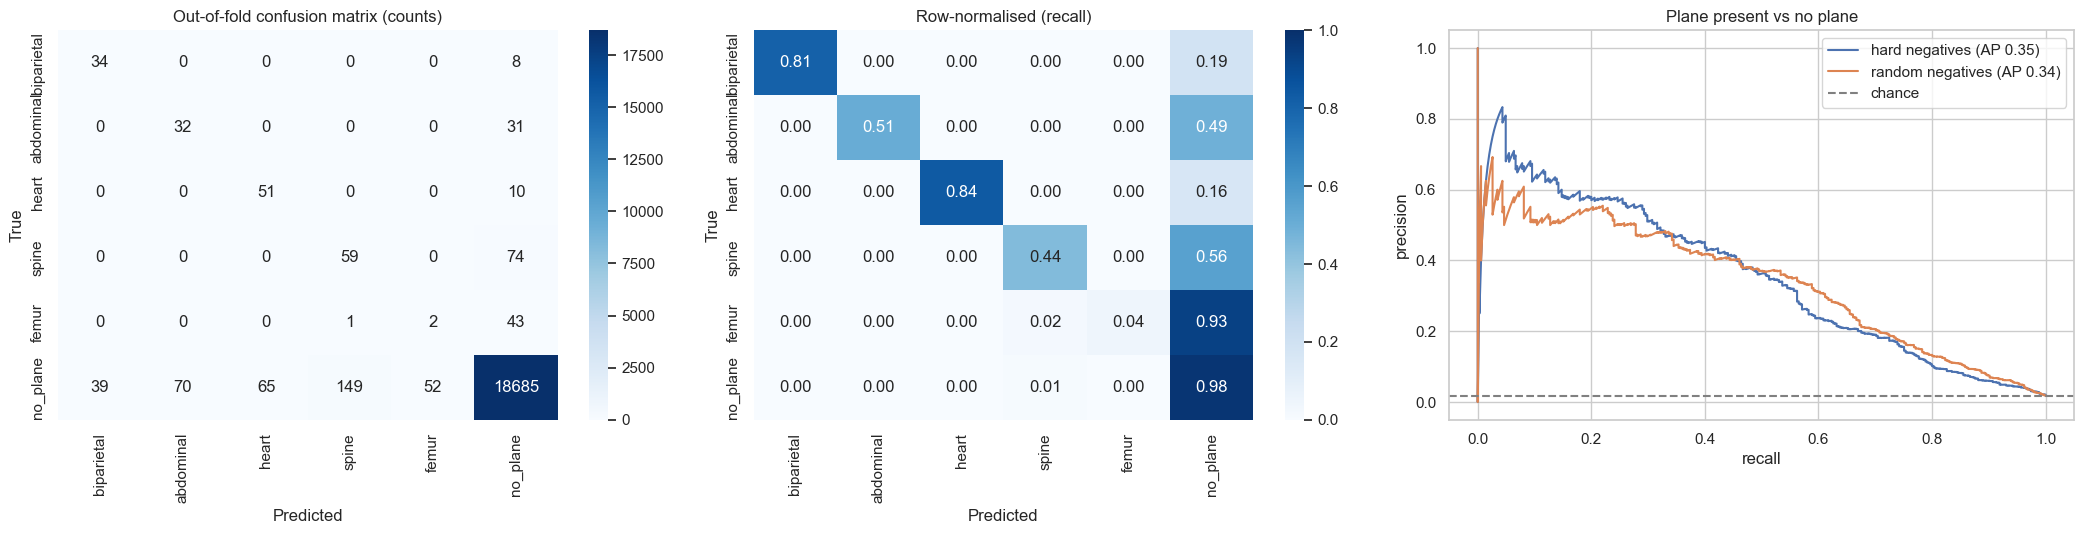

In [57]:
cm = confusion_matrix(Y, PRED, labels=range(6))
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[0].set_title("Out-of-fold confusion matrix (counts)")
sns.heatmap(cm / cm.sum(1, keepdims=True).clip(min=1), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            ax=axes[1], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[1].set_title("Row-normalised (recall)")
for ax in axes[:2]:
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for cfg in [BEST] + [c for c in CONFIGS if c != BEST and c.backbone == BEST.backbone and c.head == BEST.head and c.C == BEST.C]:
    Ps = apply_params(cfg)[0]
    pr, rc, _ = precision_recall_curve(Y != NO_PLANE, 1 - Ps[:, NO_PLANE])
    axes[2].plot(rc, pr, label=f"{cfg.negatives} negatives (AP {average_precision_score(Y != NO_PLANE, 1 - Ps[:, NO_PLANE]):.2f})")
axes[2].axhline((Y != NO_PLANE).mean(), ls="--", c="gray", label="chance")
axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Plane present vs no plane")
axes[2].legend()
plt.tight_layout()
plt.show()

### 4.3 What a Sweep Looks Like to the Model

Smoothed P(plane) along three sweeps, with the true plane frames shaded and the tuned frame threshold. This shows whether false alarms are isolated spikes or sit next to real planes.

We pick the three sweeps with the most plane frames and plot each frame's P(plane) along the sweep. The dashed line is the frame threshold τ from that sweep's fold.

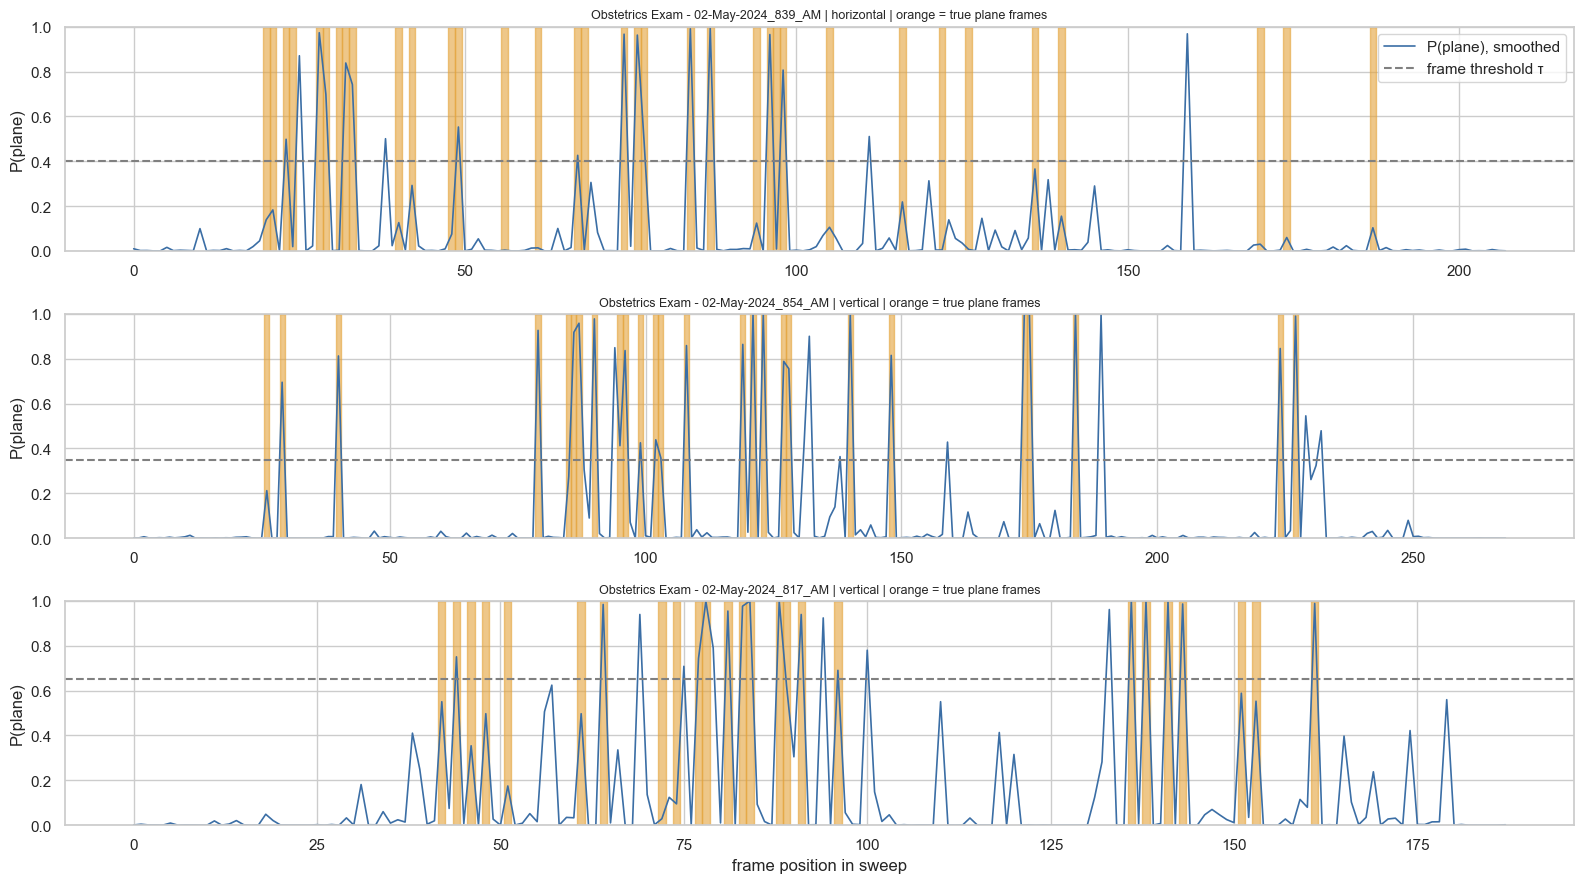

In [58]:
show = (per_video[per_video["has_plane"]].sort_values("plane_frames", ascending=False).index[:3].tolist())
fig, axes = plt.subplots(len(show), 1, figsize=(16, 3 * len(show)), squeeze=False)
for ax, vid in zip(axes[:, 0], show):
    idx = frames.index[frames["video"] == vid].values
    idx = idx[np.argsort(frames["pos"].values[idx])]
    f = frames.loc[idx[0], "fold"]
    ax.plot(frames["pos"].values[idx], P_PLANE[idx], c="#3b6ea5", lw=1.2, label="P(plane), smoothed")
    for i in idx[Y[idx] != NO_PLANE]:
        ax.axvspan(frames["pos"][i] - 0.5, frames["pos"][i] + 0.5, color="#e4a33a", alpha=0.6)
    ax.axhline(PARAMS[BEST][f]["tau"], ls="--", c="gray", label="frame threshold τ")
    ax.set_ylim(0, 1); ax.set_ylabel("P(plane)")
    ax.set_title(f"{vid} | {frames.loc[idx[0], 'sweep_type']} | orange = true plane frames", fontsize=9)
axes[0, 0].legend(loc="upper right")
axes[-1, 0].set_xlabel("frame position in sweep")
plt.tight_layout()
plt.show()

### 4.4 Sweep-level Decision: Rescan or Not (RQ2)

A sweep is **flagged for rescan** when its sweep score (best frame, or mean of the top 3 or 5 frames, chosen per fold) is below τ_sweep (tuned per fold on inner validation for ≥ 90% sensitivity). Sensitivity = plane-containing sweeps that pass; specificity = plane-free sweeps that are flagged.

We test the decision a midwife would see: we score every sweep with the tuned sweep score, flag sweeps below the threshold for rescan, and measure sensitivity, specificity and the ROC curve.

**Step 1: Score and flag every sweep**

Each sweep's score is its highest P(plane). It is compared with the sweep threshold from its own fold, and sweeps below it are **flagged for rescan**.

In [59]:
sw = sweep_table(BEST).join(per_video[["sweep_type", "fetal_position"]])
print("Sweep score used per fold:", sw.groupby("fold")["method"].first().to_dict())

Sweep score used per fold: {0: 'top3', 1: 'max', 2: 'top3', 3: 'max', 4: 'max'}


**Step 2: Summarise the decision**

Sensitivity (plane-containing sweeps that pass), specificity (plane-free sweeps that are flagged), flag rate, and sweep-level ROC-AUC.

In [60]:
def sweep_stats(s):
    pos, neg = s[s["has_plane"]], s[~s["has_plane"]]
    return {"sweeps": len(s), "sensitivity (plane sweeps passed)": (~pos["flagged"]).mean() if len(pos) else np.nan,
            "specificity (empty sweeps flagged)": neg["flagged"].mean() if len(neg) else np.nan,
            "flag rate": s["flagged"].mean()}

SWEEP_SUMMARY = sweep_stats(sw)
SWEEP_SUMMARY["sweep ROC-AUC"] = roc_auc_score(sw["has_plane"], sw["score"])
display(pd.DataFrame([SWEEP_SUMMARY]).round(3))

,sweeps,sensitivity (plane sweeps passed),specificity (empty sweeps flagged),flag rate,sweep ROC-AUC
0,90,0.796,0.5,0.322,0.751


**Step 3: Plot the ROC curve**

Shows how sensitivity and specificity trade off as the sweep threshold changes.

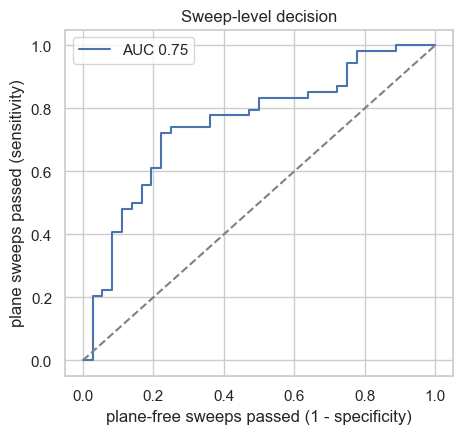

In [61]:
fpr, tpr, _ = roc_curve(sw["has_plane"], sw["score"])
plt.figure(figsize=(5, 4.5))
plt.plot(fpr, tpr, label=f"AUC {SWEEP_SUMMARY['sweep ROC-AUC']:.2f}")
plt.plot([0, 1], [0, 1], "--", c="gray")
plt.xlabel("plane-free sweeps passed (1 - specificity)"); plt.ylabel("plane sweeps passed (sensitivity)")
plt.title("Sweep-level decision"); plt.legend()
plt.show()

### 4.5 Sweep-level Frame Finding: Is a Correct Frame in the Top *k*?

We check whether the model points to a correct frame. For each sweep and each plane it really contains, we rank the sweep's frames by that plane's probability. **hit@1** means the top-ranked frame shows that plane; **hit@5** means at least one of the top 5 does.

In [62]:
hit_rows = []
for vid, idx in frames.groupby("video").indices.items():
    for c in PLANE_IDS:
        if (Y[idx] == c).any():
            ranked = Y[idx][np.argsort(-P_best[idx, c])]
            hit_rows.append({"video": vid, "plane": CLASS_NAMES[c],
                             **{f"hit@{k}": bool((ranked[:k] == c).any()) for k in TOP_K}})
HITS = pd.DataFrame(hit_rows)
display(HITS.groupby("plane")[[f"hit@{k}" for k in TOP_K]].mean().round(3)
        .assign(sweeps=HITS.groupby("plane").size()))
HIT_SUMMARY = HITS[[f"hit@{k}" for k in TOP_K]].mean()
print("All planes:", HIT_SUMMARY.round(3).to_dict(), f"over {len(HITS)} plane–sweep pairs")

,hit@1,hit@5,sweeps
plane,,,
abdominal,0.647,0.882,17
biparietal,0.818,1.000,11
femur,0.125,0.375,24
heart,0.550,0.850,20
spine,0.542,0.917,24


All planes: {'hit@1': 0.49, 'hit@5': 0.771} over 96 plane–sweep pairs


### 4.6 Error Analysis and Calibration

We look at the errors: which classes are confused most, example frames the model got confidently wrong or missed, and whether its probabilities can be taken at face value (calibration).

**Step 1: Most common mistakes**

Lists the most frequent confusions (true class → predicted class), counts false plane calls, and shows the share of them sitting right next to a real plane.

In [63]:
pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(6) for j in range(6) if i != j and cm[i, j]]
err = pd.DataFrame(pairs, columns=["true", "predicted", "count"]).sort_values("count", ascending=False)
fp = frames[(PRED != NO_PLANE) & (Y == NO_PLANE)]
print(f"False plane calls: {len(fp)} | of these next to a real plane (ambiguous): {fp['near_plane'].mean():.1%}")
display(err.head(8))

False plane calls: 375 | of these next to a real plane (ambiguous): 17.1%


,true,predicted,count
9,no_plane,spine,149
3,spine,no_plane,74
7,no_plane,abdominal,70
8,no_plane,heart,65
10,no_plane,femur,52
5,femur,no_plane,43
6,no_plane,biparietal,39
1,abdominal,no_plane,31


**Step 2: Define an image gallery**

Shows up to six frames with their true class, predicted class and P(plane).

In [64]:
def gallery(idx, title):
    idx = list(idx)[:6]
    if not idx:
        return
    fig, axes = plt.subplots(1, len(idx), figsize=(3 * len(idx), 3.4), squeeze=False)
    for ax, i in zip(axes[0], idx):
        ax.imshow(IMAGES[frames.loc[i, "row"]], cmap="gray")
        ax.set_title(f"true {CLASS_NAMES[Y[i]]}\npred {CLASS_NAMES[PRED[i]]} ({P_PLANE[i]:.2f})", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

**Step 3: Show example errors**

Two galleries: the most confident false plane calls, and the missed plane frames the model scored lowest.

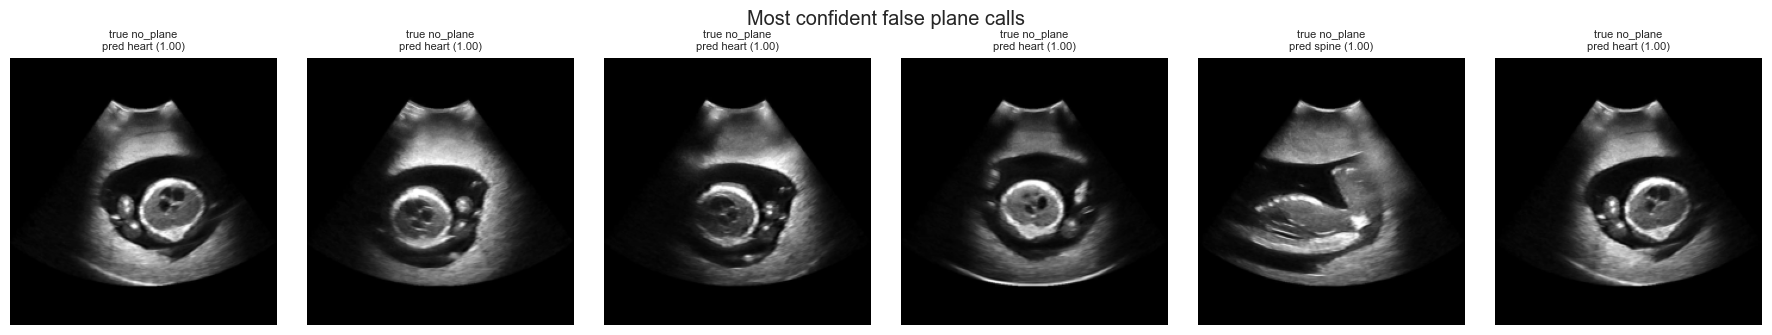

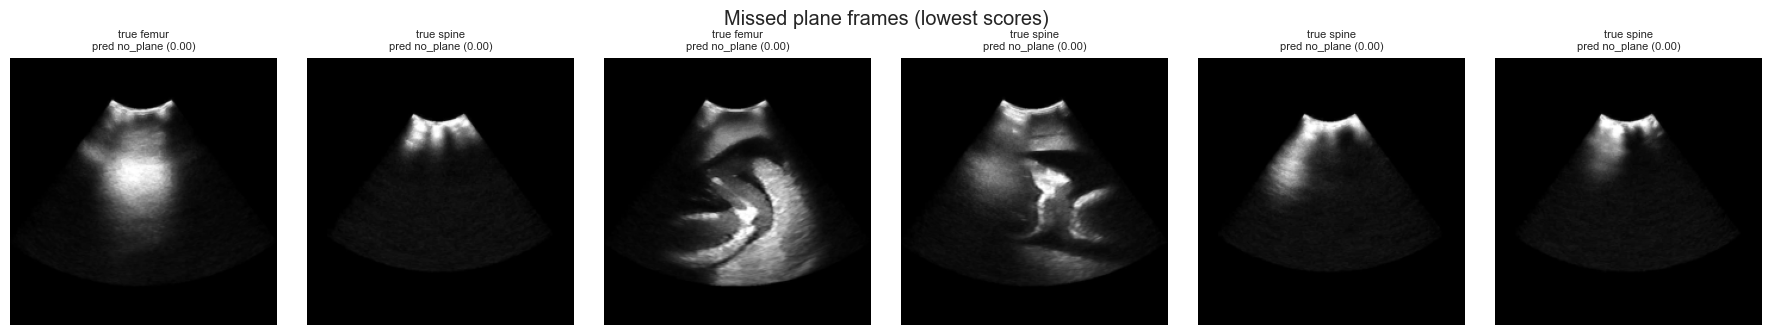

In [65]:
conf_fp = fp.index[np.argsort(-P_PLANE[fp.index])]
gallery(conf_fp, "Most confident false plane calls")
missed = frames.index[(Y != NO_PLANE) & (PRED == NO_PLANE)]
gallery(missed[np.argsort(P_PLANE[missed])], "Missed plane frames (lowest scores)")

**Step 4: Define a calibration check**

Puts predictions into 10 probability bins and compares each bin's average predicted probability with how often a plane was really present. **ECE** is the weighted average gap; 0 means perfectly calibrated.

In [66]:
def ece_curve(y_bin, prob, ax, label, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    ids = np.clip(np.digitize(prob, bins) - 1, 0, n_bins - 1)
    conf = np.array([prob[ids == b].mean() if (ids == b).any() else np.nan for b in range(n_bins)])
    acc = np.array([y_bin[ids == b].mean() if (ids == b).any() else np.nan for b in range(n_bins)])
    ece = np.nansum(np.array([(ids == b).mean() for b in range(n_bins)]) * np.abs(acc - conf))
    ax.plot([0, 1], [0, 1], "--", c="gray")
    ax.plot(conf, acc, "o-", label=f"{label} (ECE {ece:.3f})")
    return ece

**Step 5: Plot calibration**

Draws the calibration curve for frame probabilities and for sweep scores.

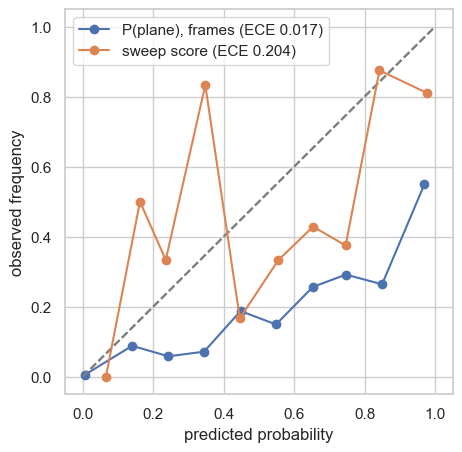

Class-weighted training inflates probabilities: thresholds are tuned, so ranking matters more than calibration.


In [67]:
fig, ax = plt.subplots(figsize=(5, 5))
ECE = ece_curve((Y != NO_PLANE).astype(float), P_PLANE, ax, "P(plane), frames")
ece_curve(sw["has_plane"].astype(float).values, sw["score"].values, ax, "sweep score")
ax.set_xlabel("predicted probability"); ax.set_ylabel("observed frequency"); ax.legend()
plt.show()
print("Class-weighted training inflates probabilities: thresholds are tuned, so ranking matters more than calibration.")

## Part 5: Robustness (RQ3)

In this part we:

1. **Results by subgroup (5.1):** out-of-fold scores for each sweep type and fetal position.
2. **Leave-one-sweep-type-out (5.2):** train without one sweep type, then test on it.

**Why:** in the field, the model will meet sweep patterns and fetal positions that differ from its training data. This shows where it is weakest.

### 5.1 Out-of-fold Results by Sweep Type and Fetal Position

We break the out-of-fold results down by sweep type and by fetal position. For each group we report the number of sweeps and plane frames, plane macro-F1, plane recall (plane frames detected as any plane) and sweep sensitivity.

In [68]:
def group_table(col):
    out = []
    for g, sub in frames.groupby(col):
        idx = sub.index.values
        s = sw[sw[col] == g]
        out.append({col: g, "sweeps": sub["video"].nunique(), "plane_frames": int((Y[idx] != NO_PLANE).sum()),
                    "plane_macro_f1": plane_f1(Y[idx], PRED[idx]),
                    "plane_recall": recall_score(Y[idx] != NO_PLANE, PRED[idx] != NO_PLANE, zero_division=0),
                    "sweep_sensitivity": sweep_stats(s)["sensitivity (plane sweeps passed)"]})
    return pd.DataFrame(out).set_index(col)

for col in ["sweep_type", "fetal_position"]:
    display(group_table(col).round(3))

,sweeps,plane_frames,plane_macro_f1,plane_recall,sweep_sensitivity
sweep_type,,,,,
diagonal 1,20,15,0.127,0.267,0.500
diagonal 2,22,45,0.265,0.311,0.667
horizontal,27,135,0.269,0.393,0.833
vertical,21,150,0.356,0.720,0.947


,sweeps,plane_frames,plane_macro_f1,plane_recall,sweep_sensitivity
fetal_position,,,,,
OA,15,38,0.298,0.500,0.778
OP,34,54,0.206,0.444,0.733
SA,15,51,0.319,0.471,0.818
SP,26,202,0.424,0.554,0.842


### 5.2 Leave-one-sweep-type-out

Train on three sweep types (with the same nested tuning), test on the fourth: performance when a midwife uses a sweep pattern the model never saw.

We hold out each sweep type in turn, train on the other types with the same nested tuning, and test on the held-out one, recording plane F1, plane recall, average precision and sweep sensitivity.

In [69]:
loso = []
for held in sorted(frames["sweep_type"].unique()):
    te = np.where(frames["sweep_type"].values == held)[0]
    tr = np.where(frames["sweep_type"].values != held)[0]
    P, p = run_split(BEST, tr, te, SEED)
    Ps = smooth(P, te, p["w"])
    pred = decide(Ps, p["tau"])
    s = sweep_scores(Ps, te, p["sweep_method"])
    s["flagged"] = s["score"] < p["tau_sweep"]
    loso.append({"held_out_sweep_type": held, "sweeps": len(s), "plane_macro_f1": plane_f1(Y[te], pred),
                 "plane_recall": recall_score(Y[te] != NO_PLANE, pred != NO_PLANE, zero_division=0),
                 "plane_AP": average_precision_score(Y[te] != NO_PLANE, 1 - Ps[:, NO_PLANE]),
                 "sweep_sensitivity": sweep_stats(s)["sensitivity (plane sweeps passed)"]})
LOSO = pd.DataFrame(loso)
display(LOSO.round(3))

,held_out_sweep_type,sweeps,plane_macro_f1,plane_recall,plane_AP,sweep_sensitivity
0,diagonal 1,20,0.203,0.333,0.231,0.875
1,diagonal 2,22,0.315,0.222,0.160,0.778
2,horizontal,27,0.249,0.178,0.135,0.944
3,vertical,21,0.180,0.380,0.298,0.895


## Part 6: Final Model and Deployment (RQ4)

In this part we:

1. **Final model (6.1):** train on all sweeps, package backbone, scaling and head into one Keras model, and save the settings the app needs.
2. **Phone export (6.2):** convert to TensorFlow Lite and measure file size and speed per frame.
3. **What the model looks at (6.3):** occlusion maps showing which image regions drive each prediction.
4. **Using the model (6.4):** score a complete sweep from its JPEG frames.

**Why:** RQ4 asks whether the model is small and fast enough for a phone. The occlusion maps check that it looks at fetal anatomy, not at borders or screen overlays.

### 6.1 Train on All Sweeps and Package One Model

The final head is trained on every sweep with the selected configuration. Smoothing window and thresholds are the medians of the five outer folds; the sweep score is the method most folds chose. The backbone, feature scaling and head are packaged as **one Keras model** that takes a preprocessed 224×224 frame. Sector crop, contrast stretch, smoothing and the sweep decision are lightweight steps saved in `pipeline_config.json`.

We train the final model on every sweep, package it as a single Keras model, check that it matches the pipeline, and save it with the settings the app needs.

**Step 1: Final settings and training**

`FINAL` takes the median smoothing window and thresholds across the 5 folds, with the window made odd so it is centred on each frame. The `BEST` head is then trained on every sweep.

In [70]:
FINAL = {k: float(np.median([p[k] for p in PARAMS[BEST].values()])) for k in ["w", "tau"]}
FINAL["w"] = int(FINAL["w"]) if int(FINAL["w"]) % 2 else int(FINAL["w"]) + 1
FINAL["sweep_method"] = pd.Series([p["sweep_method"] for p in PARAMS[BEST].values()]).mode()[0]
FINAL["tau_sweep"] = float(np.median([p["tau_sweep_by_method"][FINAL["sweep_method"]]
                                      for p in PARAMS[BEST].values()]))
head = train_model(BEST, np.arange(len(frames)), np.random.default_rng(SEED))
print(FINAL)

{'w': 1, 'tau': 0.4, 'sweep_method': 'max', 'tau_sweep': 0.5360318106887472}


**Step 2: Package one model**

`DEPLOY` chains backbone (or both backbones, concatenated, for the "concat" feature set) → a `Normalization` layer that reproduces the feature standardisation → head. A logistic-regression head is copied into a softmax `Dense` layer; any class it never saw gets a bias of −10,000, so its probability is about 0. An MLP head is reused as is.

In [71]:
inp = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="frame")
if BEST.backbone == "concat":
    z = layers.Concatenate(name="features")([get_backbone(b)(inp) for b in FEATURE_BACKBONES])
else:
    z = get_backbone(BEST.backbone)(inp)
z = layers.Normalization(mean=head["scaler"].mean_, variance=head["scaler"].var_, name="feature_scaling")(z)
if head["kind"] == "logreg":
    dense = layers.Dense(6, activation="softmax", name="plane_probs")
    out = dense(z)
    W = np.zeros((z.shape[-1], 6), np.float32)
    bias = np.full(6, -1e4, np.float32)
    W[:, head["model"].classes_] = head["model"].coef_.T
    bias[head["model"].classes_] = head["model"].intercept_
    dense.set_weights([W, bias])
else:
    out = head["model"](z)
DEPLOY = keras.Model(inp, out, name="taswira_plane_finder")

**Step 3: Check the package**

Runs 64 frames through both the packaged model and the original pipeline and prints how closely they agree.

In [72]:
check = np.arange(0, len(frames), max(1, len(frames) // 64))[:64]
x_chk = np.repeat(np.asarray(IMAGES[frames["row"].values[check]])[..., None], 3, -1).astype(np.float32)
p_pkg = DEPLOY.predict(x_chk, verbose=0)
p_ref = predict_head(head, FEATS[BEST.backbone][check])
print(f"Packaged model matches the pipeline: max prob difference {np.abs(p_pkg - p_ref).max():.4f}, "
      f"argmax agreement {(p_pkg.argmax(1) == p_ref.argmax(1)).mean():.3f}")

Packaged model matches the pipeline: max prob difference 0.0003, argmax agreement 1.000


**Step 4: Save the model and settings**

Saves `taswira_plane_finder.keras` and `pipeline_config.json`, which holds the crop box, contrast settings, smoothing window and thresholds the app also needs.

In [73]:
DEPLOY.save(OUT_DIR / "taswira_plane_finder.keras")
config = {"classes": CLASS_NAMES, "img_size": IMG_SIZE, "crop_box": CROP, "contrast_percentiles": CONTRAST_PCT,
          "backbone": BEST.backbone, "head": BEST.head, "C": BEST.C, "negatives": BEST.negatives,
          "smoothing_window": FINAL["w"], "frame_threshold": FINAL["tau"], "sweep_score": FINAL["sweep_method"], "sweep_threshold": FINAL["tau_sweep"]}
(OUT_DIR / "pipeline_config.json").write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

{
  "classes": [
    "biparietal",
    "abdominal",
    "heart",
    "spine",
    "femur",
    "no_plane"
  ],
  "img_size": 224,
  "crop_box": [
    50,
    28,
    657,
    467
  ],
  "contrast_percentiles": [
    1,
    99.5
  ],
  "backbone": "concat",
  "head": "logreg",
  "C": 0.03,
  "negatives": "hard",
  "smoothing_window": 1,
  "frame_threshold": 0.4,
  "sweep_score": "max",
  "sweep_threshold": 0.5360318106887472
}


### 6.2 TFLite Export, Size and CPU Latency

We convert the model to TensorFlow Lite for phones and measure its file size, its speed per frame and how closely it agrees with the Keras model.

**Step 1: Convert to TensorFlow Lite**

Uses the default optimisation, which compresses the weights, and saves the `.tflite` file.

In [74]:
conv = tf.lite.TFLiteConverter.from_keras_model(DEPLOY)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
tfl = conv.convert()
(OUT_DIR / "taswira_plane_finder.tflite").write_bytes(tfl)

7129744

**Step 2: Load the phone model**

Loads the TFLite model in an interpreter; `tfl_predict()` runs one frame through it.

In [75]:
interp = tf.lite.Interpreter(model_content=tfl)
interp.allocate_tensors()
inp_d, out_d = interp.get_input_details()[0], interp.get_output_details()[0]
def tfl_predict(x):
    interp.set_tensor(inp_d["index"], x[None].astype(np.float32))
    interp.invoke()
    return interp.get_tensor(out_d["index"])[0]

**Step 3: Measure speed, size and agreement**

Runs 5 warm-up predictions, then times 50 to get milliseconds per frame. Checks that TFLite and Keras predict the same class on the 64 check frames. Compare the results with the targets (< 20 MB, < 200 ms per frame).

In [76]:
for _ in range(5):
    tfl_predict(x_chk[0])
t0 = time.perf_counter()
for i in range(50):
    tfl_predict(x_chk[i % len(x_chk)])
MS = (time.perf_counter() - t0) / 50 * 1000
agree = np.mean([tfl_predict(x).argmax() == p.argmax() for x, p in zip(x_chk, p_pkg)])
DEPLOY_SUMMARY = {"params": DEPLOY.count_params(), "tflite_MB": len(tfl) / 1e6, "cpu_ms_per_frame": MS,
                  "tflite_vs_keras_agreement": agree,
                  "seconds_per_median_sweep": per_video["n_frames"].median() * MS / 1000}
display(pd.DataFrame([DEPLOY_SUMMARY]).round(3))
print("Targets: < 20 MB, < 200 ms per frame.")

,params,tflite_MB,cpu_ms_per_frame,tflite_vs_keras_agreement,seconds_per_median_sweep
0,6322921,7.13,180.238,1.0,37.76


Targets: < 20 MB, < 200 ms per frame.


### 6.3 What Does the Model Look At? (occlusion sensitivity)

A grey patch slides over the frame; the map shows how much the predicted plane's probability drops when each region is hidden. Attention on anatomy, not on sector edges or overlays, supports the model's validity.

We cover parts of each image with a grey patch and measure how much the prediction drops, which shows the regions the model relies on.

**Step 1: Define the occlusion map**

Records the model's probability for the true plane, then covers the image with a grey 32×32 patch at every position (moving 16 pixels at a time) and measures how much the probability drops. Overlapping drops are averaged into a heat map.

In [77]:
def occlusion_map(img3, cls, patch=32, stride=16):
    base_p = DEPLOY.predict(img3[None], verbose=0)[0, cls]
    coords = [(r, c) for r in range(0, IMG_SIZE - patch + 1, stride) for c in range(0, IMG_SIZE - patch + 1, stride)]
    batch = np.repeat(img3[None], len(coords), 0)
    for k, (r, c) in enumerate(coords):
        batch[k, r:r + patch, c:c + patch] = 128.0
    drops = base_p - DEPLOY.predict(batch, verbose=0, batch_size=64)[:, cls]
    heat = np.zeros((IMG_SIZE, IMG_SIZE)); cnt = np.zeros((IMG_SIZE, IMG_SIZE))
    for d, (r, c) in zip(drops, coords):
        heat[r:r + patch, c:c + patch] += d; cnt[r:r + patch, c:c + patch] += 1
    return heat / np.maximum(cnt, 1)

**Step 2: Show the maps**

Takes the first correctly predicted frame of each plane (up to 4) and shows each frame above its heat map. Red areas are what the prediction depends on most.

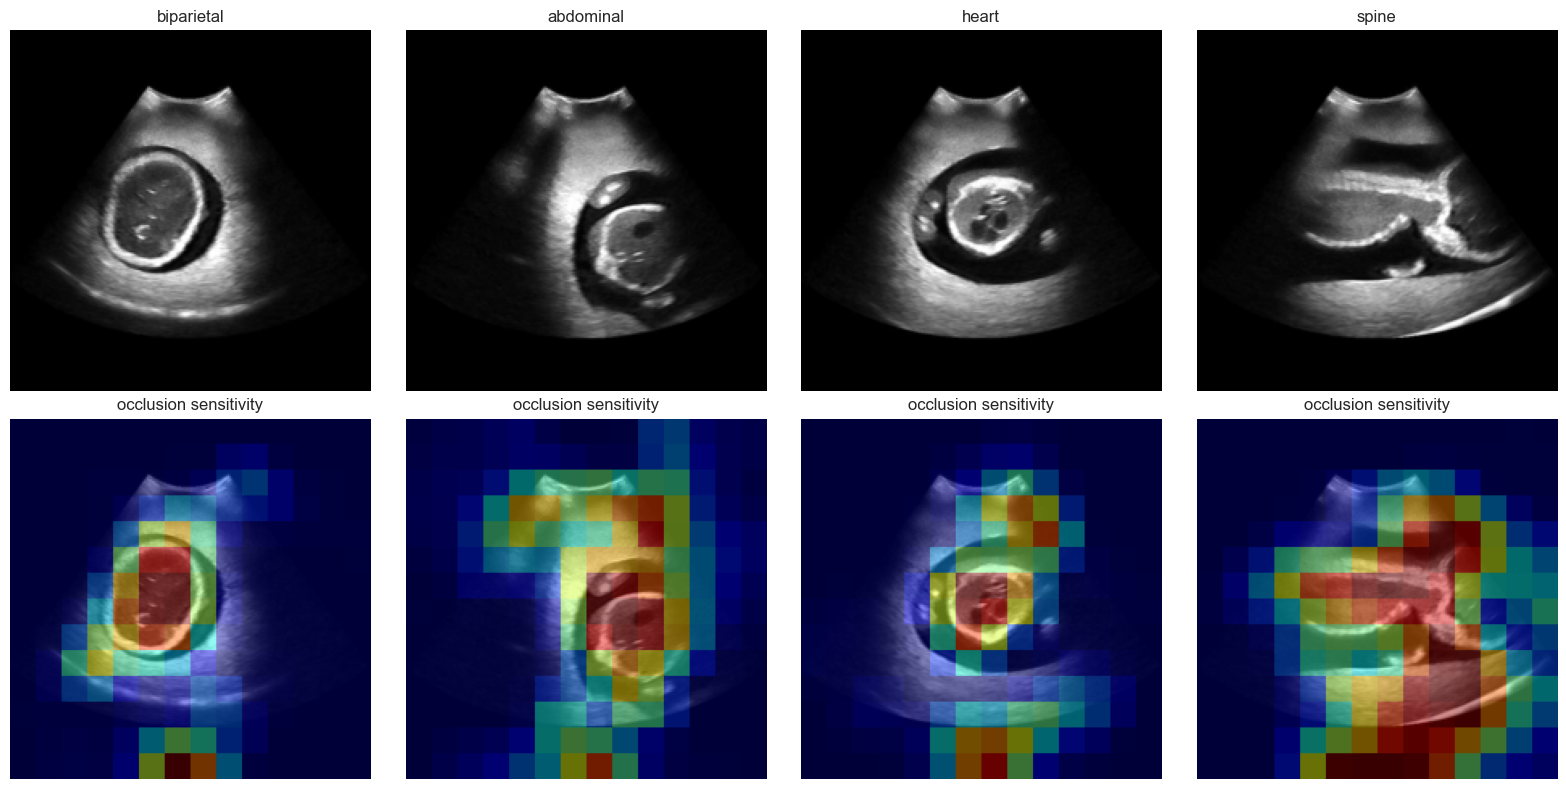

In [78]:
correct = frames.index[(Y != NO_PLANE) & (PRED == Y)]
picks = [correct[Y[correct] == c][0] for c in PLANE_IDS if (Y[correct] == c).any()][:4]
if picks:
    fig, axes = plt.subplots(2, len(picks), figsize=(4 * len(picks), 8), squeeze=False)
    for k, i in enumerate(picks):
        img3 = np.repeat(np.asarray(IMAGES[frames.loc[i, "row"]])[..., None], 3, -1).astype(np.float32)
        heat = occlusion_map(img3, Y[i])
        axes[0, k].imshow(img3[..., 0], cmap="gray"); axes[0, k].set_title(CLASS_NAMES[Y[i]])
        axes[1, k].imshow(img3[..., 0], cmap="gray")
        axes[1, k].imshow(np.clip(heat, 0, None), cmap="jet", alpha=0.45); axes[1, k].set_title("occlusion sensitivity")
        for ax in axes[:, k]:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

### 6.4 Using the Model on a New Sweep

The complete inference path, as a midwife-facing app would run it.

We wrap the whole pipeline in one function, `score_sweep()`, and run it on one sweep.

**Step 1: Define the full inference path**

`score_sweep()` takes a sweep's JPEG frames in order. It preprocesses them, runs `DEPLOY`, smooths the probabilities, and returns `rescan` (True if the best P(plane) is below the sweep threshold), `sweep_score`, and the best frame and probability for each plane.

In [79]:
def score_sweep(jpeg_paths):
    # Returns per-frame plane probabilities, the best frame per plane, and the rescan decision.
    x = np.stack([np.repeat(preprocess(Image.open(p).convert("L"))[..., None], 3, -1) for p in jpeg_paths]).astype(np.float32)
    P = DEPLOY.predict(x, verbose=0, batch_size=64)
    w = FINAL["w"]
    if w > 1:
        P = np.stack([np.convolve(np.pad(P[:, c], (w // 2, w // 2), mode="edge"), np.ones(w) / w, mode="valid")
                      for c in range(6)], axis=1)
    p_plane = 1 - P[:, NO_PLANE]
    best = {CLASS_NAMES[c]: {"frame": int(P[:, c].argmax()), "prob": float(P[:, c].max())} for c in PLANE_IDS}
    k = 1 if FINAL["sweep_method"] == "max" else int(FINAL["sweep_method"][3:])
    sweep_score = float(np.sort(p_plane)[::-1][:k].mean())
    return {"rescan": bool(sweep_score < FINAL["tau_sweep"]), "sweep_score": sweep_score,
            "best_frames": best}

**Step 2: Try it on one sweep**

This sweep was part of the final training data, so the result only demonstrates the interface, not performance.

In [80]:
demo_vid = per_video[per_video["has_plane"]].index[0]
demo_paths = frames.loc[frames["video"] == demo_vid].sort_values("pos")["path"].tolist()
print("Demo sweep (seen in final training, so this only demonstrates the interface):", demo_vid)
print(json.dumps(score_sweep(demo_paths), indent=2))

Demo sweep (seen in final training, so this only demonstrates the interface): Obstetrics Exam - 02-May-2024_1144_AM
{
  "rescan": false,
  "sweep_score": 0.9980812072753906,
  "best_frames": {
    "biparietal": {
      "frame": 147,
      "prob": 0.15569427609443665
    },
    "abdominal": {
      "frame": 245,
      "prob": 0.07896221429109573
    },
    "heart": {
      "frame": 200,
      "prob": 0.9980732202529907
    },
    "spine": {
      "frame": 90,
      "prob": 0.015854453667998314
    },
    "femur": {
      "frame": 279,
      "prob": 0.9873790144920349
    }
  }
}


## Part 8: Extra Data Sources (RQ5, version 3.2)

In this part we:

1. **Load two real-image datasets** that sit next to this notebook (8.1–8.3).
2. **Experiment A (8.5–8.6):** add real Spanish hospital images to training and test on the same NatalIA sweeps and folds as before, so any change is due to the extra data alone.
3. **Experiment B (8.7–8.8):** test the final models on real scans from five African countries.

**Why:** the model has seen only 42–134 dummy examples of each view. Real images could teach it anatomy better (Experiment A), and only real African scans can show whether it works outside the training dummy (Experiment B).

**Matching the labels.** The datasets name views differently. We map them to NatalIA's classes:

| NatalIA class | FETAL_PLANES_DB (Spain) | African set |
|---|---|---|
| biparietal (head) | Fetal brain, **trans-thalamic** plane only | brain |
| abdominal | Fetal abdomen | abdomen |
| heart | Fetal thorax | thorax |
| femur | Fetal femur | femur |
| spine | (none) | (none) |
| no plane | Other, maternal cervix | (none) |

Two assumptions to check in 8.4: that the "thorax" images show the heart (four-chamber) view, and that the African "brain" images are head views comparable to NatalIA's biparietal plane.

### 8.1 Settings

**Step 1: How much Spanish data to add**

`SPAIN_CAPS` are the numbers of Spanish images per class added to training (the baseline, 0, is the v3.1 result). Smaller sets are subsets of larger ones, so the comparison is clean.

In [81]:
SPAIN_CAPS = [100, 400]       # Spanish images per class added to training (0 = v3.1 baseline)
EXT_TARGETS = ["biparietal", "abdominal", "heart", "femur"]   # views shared with the extra datasets
EXT_IDS = [CLASS_NAMES.index(c) for c in EXT_TARGETS]
COUNTRIES = ["algeria", "egypt", "ghana", "malawi", "uganda"]
IMG_EXT = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}
import tarfile, hashlib

### 8.2 Locate (and if needed unpack) the two datasets

**Step 1: Helper functions**

We search the notebook folder for each dataset's metadata file; if it is missing, we unpack the archive found next to the notebook. `pick_col` finds a column by name even if the exact spelling differs.

In [82]:
def search(pattern, exclude=("cache", "outputs")):
    return sorted(p for p in NOTEBOOK_DIR.rglob(pattern) if not any(x in p.parts for x in exclude))

def unpack(archives, target):
    for a in archives:
        print(f"Extracting {a.name} -> {target} (can take a few minutes) ...")
        target.mkdir(exist_ok=True)
        if a.suffix == ".zip":
            with zipfile.ZipFile(a) as zf:
                zf.extractall(target)
        else:
            with tarfile.open(a) as tf_:
                tf_.extractall(target)

def read_table(path):
    if path.suffix.lower() in {".xlsx", ".xls"}:
        df = pd.read_excel(path)
    else:
        df = pd.read_csv(path, sep=None, engine="python")   # detects ; or ,
    df.columns = [str(c).strip() for c in df.columns]
    return df

def pick_col(df, exact, contains=(), avoid=()):
    low = {c.lower(): c for c in df.columns}
    for e in exact:
        if e in low:
            return low[e]
    for k in contains:
        for c in df.columns:
            if k in c.lower() and not any(a in c.lower() for a in avoid):
                return c
    return None

def image_index(root):
    idx = {}
    for p in root.rglob("*"):
        if p.suffix.lower() in IMG_EXT:
            idx.setdefault(p.name.lower(), p)
            idx.setdefault(p.stem.lower(), p)
    return idx

def resolve(name, idx):
    n = str(name).strip()
    for key in (n.lower(), pathlib.Path(n).name.lower(), pathlib.Path(n).stem.lower(), (n + ".png").lower()):
        if key in idx:
            return str(idx[key])
    return None

**Step 2: Find or unpack each dataset**

In [83]:
spain_meta = search("FETAL_PLANES_DB_data.csv") or search("FETAL_PLANES_DB_data.xlsx")
if not spain_meta:
    unpack([z for z in NOTEBOOK_DIR.glob("*.zip") if "fetal_planes" in z.name.lower()], NOTEBOOK_DIR / "FETAL_PLANES_DB")
    spain_meta = search("FETAL_PLANES_DB_data.csv") or search("FETAL_PLANES_DB_data.xlsx")

AFRICA_DIR = NOTEBOOK_DIR / "African_planes"
if not AFRICA_DIR.exists():
    unpack([a for a in NOTEBOOK_DIR.glob("*.tar.xz")] + [z for z in NOTEBOOK_DIR.glob("*.zip") if "zenodo_dataset" in z.name.lower()],
           AFRICA_DIR)
africa_meta = sorted(p for p in AFRICA_DIR.rglob("*") if p.suffix.lower() in {".csv", ".xlsx"}) if AFRICA_DIR.exists() else []

HAVE_SPAIN, HAVE_AFRICA = bool(spain_meta), bool(africa_meta)
print("Spanish metadata:", spain_meta[0] if HAVE_SPAIN else "NOT FOUND - put FETAL_PLANES_ZENODO.zip next to this notebook")
print("African metadata:", africa_meta if HAVE_AFRICA else "NOT FOUND - put Zenodo_dataset.tar.xz next to this notebook")

Extracting FETAL_PLANES_ZENODO.zip -> c:\Users\OMokera\Desktop\Moringa\fetal_ultrasound_capstone\FETAL_PLANES_DB (can take a few minutes) ...
Extracting Zenodo_dataset.tar.xz -> c:\Users\OMokera\Desktop\Moringa\fetal_ultrasound_capstone\African_planes (can take a few minutes) ...
Spanish metadata: c:\Users\OMokera\Desktop\Moringa\fetal_ultrasound_capstone\FETAL_PLANES_DB\FETAL_PLANES_DB_data.csv
African metadata: [WindowsPath('c:/Users/OMokera/Desktop/Moringa/fetal_ultrasound_capstone/African_planes/Zenodo_dataset/African_planes_database.csv')]


### 8.3 Read the metadata and map the labels

**Step 1: Spanish images**

Each row gives an image name, its plane and (for brain images) the brain sub-plane. Only the trans-thalamic brain plane counts as the head view; other brain planes are left out, because they are neither the target view nor clearly "no plane".

In [84]:
def map_spain(plane, brain):
    p, b = str(plane).lower(), str(brain).lower()
    if "abdom" in p: return "abdominal"
    if "femur" in p: return "femur"
    if "thorax" in p: return "heart"
    if "brain" in p: return "biparietal" if "thalamic" in b else None
    if "cervix" in p or p.strip() == "other": return "no_plane"
    return None

spain = pd.DataFrame()
if HAVE_SPAIN:
    m = read_table(spain_meta[0])
    print("Columns:", list(m.columns))
    c_img = pick_col(m, ["image_name"], ["image", "file"])
    c_plane = pick_col(m, ["plane"], ["plane"], avoid=["brain"])
    c_brain = pick_col(m, ["brain_plane"], ["brain"])
    c_pat = pick_col(m, ["patient_num"], ["patient"])
    idx = image_index(spain_meta[0].parent)
    spain = pd.DataFrame({"path": [resolve(n, idx) for n in m[c_img]],
                          "cls": [map_spain(p, b) for p, b in zip(m[c_plane], m[c_brain] if c_brain else [""] * len(m))],
                          "patient": m[c_pat].astype(str) if c_pat else "unknown"})
    print(f"Rows: {len(spain)} | images found: {spain['path'].notna().sum()} | mapped: {spain['cls'].notna().sum()}")
    spain = spain.dropna(subset=["path", "cls"]).reset_index(drop=True)
    display(spain["cls"].value_counts().rename("Spanish images per class"))

Columns: ['Image_name', 'Patient_num', 'Plane', 'Brain_plane', 'Operator', 'US_Machine', 'Train']
Rows: 12400 | images found: 12400 | mapped: 10946


cls
no_plane      5839
heart         1718
biparietal    1638
femur         1040
abdominal      711
Name: Spanish images per class, dtype: int64

**Step 2: African images**

The country is taken from a centre/country column if there is one, otherwise from the folder or file name. The output lists what was found, so the mapping can be checked.

In [85]:
def map_africa(plane):
    p = str(plane).lower()
    if "abdom" in p: return "abdominal"
    if "femur" in p: return "femur"
    if "thorax" in p: return "heart"
    if "brain" in p or "head" in p: return "biparietal"
    return None

def find_country(*texts):
    t = " ".join(str(x).lower() for x in texts)
    return next((c for c in COUNTRIES if c in t), "unknown")

africa = pd.DataFrame()
if HAVE_AFRICA:
    m = pd.concat([read_table(p) for p in africa_meta if p.suffix.lower() in {".csv", ".xlsx"}], ignore_index=True)
    print("Columns:", list(m.columns))
    c_img = pick_col(m, ["filename", "image_name", "image"], ["file", "image", "name"])
    c_plane = pick_col(m, ["plane"], ["plane", "class", "label"])
    c_pat = pick_col(m, ["patient_num", "patient"], ["patient"])
    c_ctry = pick_col(m, ["center", "centre", "country"], ["center", "centre", "country", "site"])
    idx = image_index(AFRICA_DIR)
    paths = [resolve(n, idx) for n in m[c_img]]
    africa = pd.DataFrame({
        "path": paths,
        "cls": [map_africa(p) for p in m[c_plane]],
        "country": [find_country(m.loc[i, c_ctry] if c_ctry else "", p or "", m.loc[i, c_img]) for i, p in enumerate(paths)],
    })
    africa["patient"] = africa["country"] + ":" + (m[c_pat].astype(str) if c_pat else pd.Series(range(len(m))).astype(str))
    print(f"Rows: {len(africa)} | images found: {africa['path'].notna().sum()} | mapped: {africa['cls'].notna().sum()}")
    if c_ctry:
        print("Centre/country values:", m[c_ctry].astype(str).value_counts().to_dict())
    africa = africa.dropna(subset=["path", "cls"]).reset_index(drop=True)
    display(pd.crosstab(africa["country"], africa["cls"], margins=True))
    if (africa["country"] == "unknown").any():
        print("Some images have no country: send the 'Centre/country values' above so the mapping can be fixed.")

Columns: ['Patient_num', 'Plane', 'Train', 'Center', 'Filename']
Rows: 450 | images found: 450 | mapped: 450
Centre/country values: {'Algeria': 100, 'Egypt': 100, 'Malawi': 100, 'Uganda': 75, 'Ghana': 75}


cls,abdominal,biparietal,femur,heart,All
country,,,,,
algeria,25,25,25,25,100
egypt,25,25,25,25,100
ghana,25,25,25,0,75
malawi,25,25,25,25,100
uganda,25,25,25,0,75
All,125,125,125,75,450


### 8.4 Check the label mapping by eye

One example per view from each source, after the same clean-up as NatalIA (crop to the image area, stretch contrast, pad to square). **Check that each column shows the same view**: if the Spanish "heart" images are not heart views, change `map_spain` in 8.3.

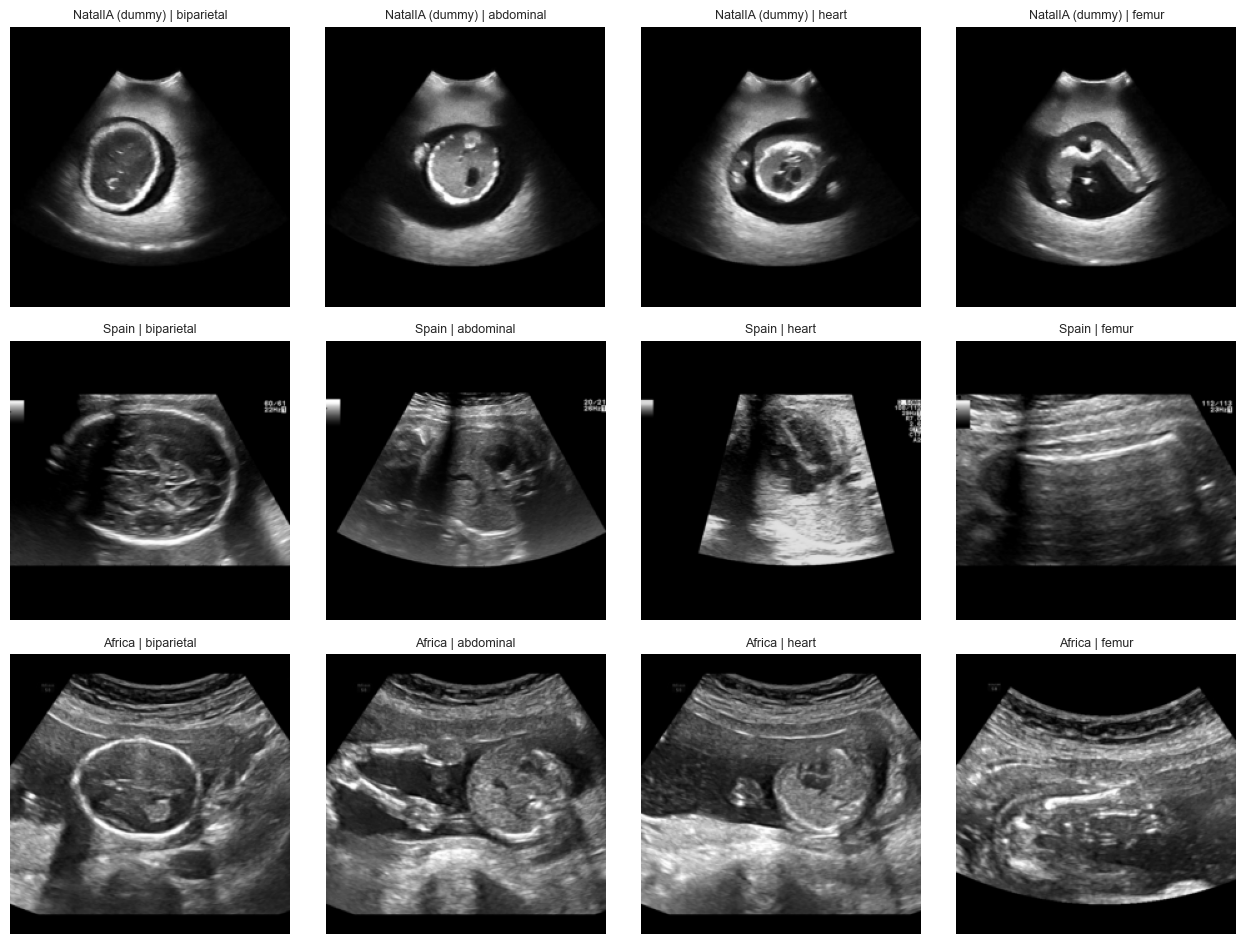

In [86]:
def preprocess_external(img_gray):
    # Like `preprocess`, but the crop box is found per image (other datasets differ in size and layout).
    a = np.asarray(img_gray, dtype=np.float32)
    mask = a > 8
    rows, cols = np.where(mask.mean(1) > 0.02)[0], np.where(mask.mean(0) > 0.02)[0]
    if len(rows) > 10 and len(cols) > 10:
        a = a[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1]
    lo, hi = np.percentile(a, CONTRAST_PCT)
    a = np.clip((a - lo) / max(hi - lo, 1e-6) * 255.0, 0, 255).astype(np.uint8)
    h, w = a.shape
    s = max(h, w)
    sq = np.zeros((s, s), np.uint8)
    sq[(s - h) // 2:(s - h) // 2 + h, (s - w) // 2:(s - w) // 2 + w] = a
    return np.asarray(Image.fromarray(sq).resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))

sources = [("NatalIA (dummy)", None)] + [(n, d) for n, d in [("Spain", spain), ("Africa", africa)] if len(d)]
fig, axes = plt.subplots(len(sources), len(EXT_TARGETS), figsize=(3.2 * len(EXT_TARGETS), 3.2 * len(sources)), squeeze=False)
for r, (name, d) in enumerate(sources):
    for c, cls in enumerate(EXT_TARGETS):
        ax = axes[r, c]
        ax.axis("off")
        if d is None:
            rows_ = frames.index[frames["label"] == CLASS_NAMES.index(cls)]
            if len(rows_):
                ax.imshow(IMAGES[frames.loc[rows_[0], "row"]], cmap="gray")
        else:
            sub = d[d["cls"] == cls]
            if len(sub):
                ax.imshow(preprocess_external(Image.open(sub["path"].iloc[0]).convert("L")), cmap="gray")
        ax.set_title(f"{name} | {cls}", fontsize=9)
plt.tight_layout()
plt.show()

### 8.5 Features for the extra images (cached)

**Step 1: Choose the Spanish images to add**

For each class we shuffle once and take the first 100 or 400, so the 100-image set is part of the 400-image set.

In [87]:
SPAIN_SETS = {}
if len(spain):
    order = spain.sample(frac=1, random_state=SEED).groupby("cls", group_keys=False)
    for cap in SPAIN_CAPS:
        SPAIN_SETS[cap] = order.apply(lambda g: g.head(cap)).index.values
    spain_used = spain.loc[SPAIN_SETS[max(SPAIN_CAPS)]].reset_index(drop=True)
    SPAIN_SETS = {cap: np.flatnonzero(spain_used["path"].isin(spain.loc[ix, "path"])) for cap, ix in SPAIN_SETS.items()}
    display(pd.DataFrame({cap: spain_used.loc[ix, "cls"].value_counts() for cap, ix in SPAIN_SETS.items()})
            .rename(columns=lambda c: f"{c} per class").fillna(0).astype(int))
else:
    spain_used = spain

,100 per class,400 per class
cls,,
abdominal,100,400
biparietal,100,400
femur,100,400
heart,100,400
no_plane,100,400


**Step 2: Compute features with the same backbones**

The same frozen backbones as Part 2, so all images live in the same feature space. Results are cached in `cache/`.

In [88]:
def ext_features(df, tag):
    if not len(df):
        return {}
    key = hashlib.md5((tag + cfg_key + "|".join(df["path"])).encode()).hexdigest()[:10]
    out = {}
    for b in FEATURE_BACKBONES:
        path = CACHE_DIR / f"ext_{tag}_{b}_{key}.npy"
        if path.exists():
            out[b] = np.load(path).astype(np.float32)
            continue
        model = get_backbone(b)
        F = np.zeros((len(df), model.output_shape[-1]), np.float32)
        t0 = time.time()
        for s in range(0, len(df), EMB_BATCH):
            batch = [preprocess_external(Image.open(p).convert("L")) for p in df["path"].iloc[s:s + EMB_BATCH]]
            x = np.repeat(np.stack(batch)[..., None], 3, -1).astype(np.float32)
            F[s:s + EMB_BATCH] = model.predict(x, verbose=0)
        np.save(path, F.astype(np.float16))
        print(f"{tag} | {b}: {F.shape} in {time.time() - t0:.0f}s")
        out[b] = F
        del model
        keras.backend.clear_session()
    out["concat"] = np.hstack([out[b] for b in FEATURE_BACKBONES])
    return out

FEATS_SPAIN = ext_features(spain_used, "spain")
FEATS_AFRICA = ext_features(africa, "africa")
Y_SPAIN = spain_used["cls"].map(CLASS_NAMES.index).values if len(spain_used) else np.array([], int)
Y_AFRICA = africa["cls"].map(CLASS_NAMES.index).values if len(africa) else np.array([], int)
print({k: v.shape for k, v in FEATS_SPAIN.items()}, {k: v.shape for k, v in FEATS_AFRICA.items()})

spain | efficientnetb0: (2000, 1280) in 64s
spain | mobilenetv2: (2000, 1280) in 48s
africa | efficientnetb0: (450, 1280) in 11s
africa | mobilenetv2: (450, 1280) in 9s
{'efficientnetb0': (2000, 1280), 'mobilenetv2': (2000, 1280), 'concat': (2000, 2560)} {'efficientnetb0': (450, 1280), 'mobilenetv2': (450, 1280), 'concat': (450, 2560)}


### 8.6 Experiment A: Does Extra Real Data Help?

**Step 1: Training with extra images**

Same as `train_model`, except the Spanish images are always added to the training set. They are never tested on. The NatalIA sampling uses the same random draws as v3.1, so with no Spanish images this reproduces the baseline exactly.

In [89]:
def train_model_ext(cfg, idx, rng, Xe, ye):
    X = FEATS[cfg.backbone]
    tr, pool, n_pos = sample_training(idx, rng)
    def fit(rows):
        if len(ye):
            return fit_head(cfg.head, np.vstack([X[rows], Xe]), np.concatenate([Y[rows], ye]), cfg.C)
        return fit_head(cfg.head, X[rows], Y[rows], cfg.C)
    h = fit(tr)
    if cfg.negatives == "hard":
        rest = np.setdiff1d(pool, tr)
        if len(rest):
            p_plane = 1 - predict_head(h, X[rest])[:, NO_PLANE]
            tr = np.concatenate([tr, rest[np.argsort(-p_plane)[:HARD_NEG_RATIO * n_pos]]])
            h = fit(tr)
    return h

def run_split_ext(cfg, train_idx, test_idx, seed, Xe, ye):
    rng = np.random.default_rng(seed)
    in_tr, in_val = inner_split(train_idx, seed)
    h = train_model_ext(cfg, in_tr, rng, Xe, ye)
    params = tune(predict_head(h, FEATS[cfg.backbone][in_val]), in_val)
    h = train_model_ext(cfg, train_idx, rng, Xe, ye)
    return predict_head(h, FEATS[cfg.backbone][test_idx]), params

**Step 2: Run the same 5 folds with 100 and 400 Spanish images per class**

The selected v3.1 configuration (`BEST`) is used throughout. The baseline (0 Spanish images) is the v3.1 result itself.

In [90]:
RUNS = {0: (OOF[BEST], PARAMS[BEST])}
if len(spain_used):
    for cap in SPAIN_CAPS:
        Xe, ye = FEATS_SPAIN[BEST.backbone][SPAIN_SETS[cap]], Y_SPAIN[SPAIN_SETS[cap]]
        P_oof, params = np.zeros((len(frames), 6)), {}
        t0 = time.time()
        for f in range(frames["fold"].max() + 1):
            te, tr = np.where(frames["fold"].values == f)[0], np.where(frames["fold"].values != f)[0]
            P_oof[te], params[f] = run_split_ext(BEST, tr, te, SEED + f, Xe, ye)
        RUNS[cap] = (P_oof, params)
        print(f"+{cap} Spanish images per class: done ({time.time() - t0:.0f}s)")

+100 Spanish images per class: done (67s)
+400 Spanish images per class: done (81s)


**Step 3: Compare with the v3.1 baseline**

Same folds, same thresholds procedure. `folds_better` counts the folds where the extra data beat the baseline.

,Spanish images per class,plane macro-F1,95% CI,folds better than baseline,plane-present AP,sweep hit@5,sweep sensitivity,sweep specificity,inner-val F1 (selection)
0,0,0.388,0.316–0.444,—,0.352,0.771,0.796,0.500,0.406
1,100,0.399,0.313–0.459,3/5,0.367,0.802,0.778,0.556,0.397
2,400,0.416,0.333–0.476,3/5,0.351,0.781,0.796,0.472,0.397


,baseline,+100,+400
F1 per view,,,
biparietal,0.591,0.591,0.661
abdominal,0.388,0.361,0.393
heart,0.576,0.600,0.553
spine,0.345,0.373,0.369
femur,0.040,0.071,0.103


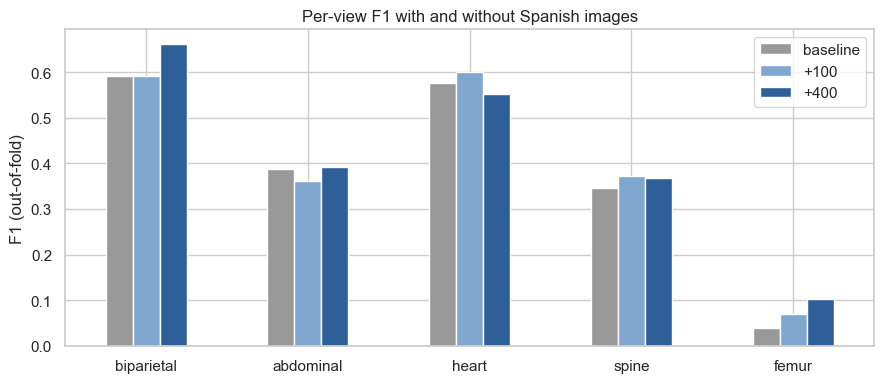

Best amount of Spanish data on inner validation: 0 per class  (adding Spanish images did not help on validation)


In [91]:
def evaluate_run(P_oof, params):
    pred = np.full(len(frames), NO_PLANE)
    P_s = np.zeros_like(P_oof)
    sw_parts = []
    for f, p in params.items():
        te = np.where(frames["fold"].values == f)[0]
        P_s[te] = smooth(P_oof[te], te, p["w"])
        pred[te] = decide(P_s[te], p["tau"])
        s = sweep_scores(P_s[te], te, p["sweep_method"])
        s["flagged"] = s["score"] < p["tau_sweep_by_method"][p["sweep_method"]]
        sw_parts.append(s)
    swr = pd.concat(sw_parts)
    hits = []
    for vid, ix in frames.groupby("video").indices.items():
        for c in PLANE_IDS:
            if (Y[ix] == c).any():
                hits.append((Y[ix][np.argsort(-P_s[ix, c])][:5] == c).any())
    per_plane = f1_score(Y, pred, labels=PLANE_IDS, average=None, zero_division=0)
    folds = [plane_f1(Y[frames["fold"].values == f], pred[frames["fold"].values == f]) for f in sorted(params)]
    return {"pred": pred, "P_s": P_s, "plane_f1": plane_f1(Y, pred), "folds": np.array(folds),
            "AP": average_precision_score(Y != NO_PLANE, 1 - P_s[:, NO_PLANE]),
            "hit@5": np.mean(hits), "sens": (~swr.loc[swr["has_plane"], "flagged"]).mean(),
            "spec": swr.loc[~swr["has_plane"], "flagged"].mean(),
            "per_plane": dict(zip([CLASS_NAMES[c] for c in PLANE_IDS], per_plane)),
            "inner_val": np.mean([p["val_score"] for p in params.values()])}

EVAL = {cap: evaluate_run(*RUNS[cap]) for cap in RUNS}
base = EVAL[0]
rows = []
for cap, e in EVAL.items():
    lo, hi = boot_ci(lambda i, pr=e["pred"]: plane_f1(Y[i], pr[i]))
    rows.append({"Spanish images per class": cap, "plane macro-F1": e["plane_f1"], "95% CI": f"{lo:.3f}–{hi:.3f}",
                 "folds better than baseline": "—" if cap == 0 else f"{(e['folds'] > base['folds']).sum()}/{len(e['folds'])}",
                 "plane-present AP": e["AP"], "sweep hit@5": e["hit@5"],
                 "sweep sensitivity": e["sens"], "sweep specificity": e["spec"],
                 "inner-val F1 (selection)": e["inner_val"]})
A_RESULTS = pd.DataFrame(rows)
display(A_RESULTS.round(3))

per_plane = pd.DataFrame({f"+{cap}" if cap else "baseline": e["per_plane"] for cap, e in EVAL.items()})
display(per_plane.round(3).rename_axis("F1 per view"))
ax = per_plane.plot.bar(figsize=(9, 4), rot=0, color=["#999999", "#7fa7d0", "#2f5f98"][:per_plane.shape[1]])
ax.set_ylabel("F1 (out-of-fold)"); ax.set_title("Per-view F1 with and without Spanish images")
plt.tight_layout(); plt.show()

BEST_CAP = max(EVAL, key=lambda c: EVAL[c]["inner_val"])   # chosen on inner validation, not on test folds
B_CAP = max([c for c in EVAL if c > 0], key=lambda c: EVAL[c]["inner_val"], default=0)  # best non-zero amount, for 8.7
print(f"Best amount of Spanish data on inner validation: {BEST_CAP} per class"
      + ("  (adding Spanish images did not help on validation)" if BEST_CAP == 0 else ""))

#### Experiment A: interpretation

TODO: did the extra images raise plane macro-F1, and in how many folds? Which views gained most (the thigh bone is the one to watch)? Did false alarms (AP, sweep specificity) improve or get worse? If nothing improved, say so: real hospital images and dummy sweeps may simply look too different.

### 8.7 Experiment B: Does It Work on Real African Scans?

**Step 1: Train the final models and score the African images**

Two final models, both trained on **all** NatalIA sweeps: one on NatalIA only (as in Part 6), one with the Spanish images (the amount that scored best on inner validation in 8.6). Both are shown even if the Spanish images did not help on the dummy sweeps, because real scans are a different test. Every African image shows one of the four shared views, so we ask two questions:

- **Detected:** does the model rate the image as a key view (P(plane) ≥ the frame threshold from Part 6)?
- **Right view:** among the four shared views, does it name the correct one?

In [92]:
B_MODELS = {"NatalIA only": (np.zeros((0, FEATS[BEST.backbone].shape[1])), np.array([], int))}
if len(spain_used) and B_CAP:
    # Always compared on African scans, even if the Spanish images did not help on the dummy sweeps
    B_MODELS[f"NatalIA + Spain ({B_CAP}/class)"] = (FEATS_SPAIN[BEST.backbone][SPAIN_SETS[B_CAP]],
                                                 Y_SPAIN[SPAIN_SETS[B_CAP]])

B_PRED = {}
if len(africa):
    Xa = FEATS_AFRICA[BEST.backbone]
    for name, (Xe, ye) in B_MODELS.items():
        h = train_model_ext(BEST, np.arange(len(frames)), np.random.default_rng(SEED), Xe, ye)
        P = predict_head(h, Xa)
        view = np.array(EXT_IDS)[P[:, EXT_IDS].argmax(1)]
        B_PRED[name] = {"P": P, "detected": (1 - P[:, NO_PLANE]) >= FINAL["tau"], "view": view}

**Step 2: Results overall and by country**

95% confidence intervals come from resampling **patients**. With 25 patients per country, country-level numbers are indicative only.

,model,images,detected as a key view,right view (accuracy),right view (macro-F1),macro-F1 95% CI
0,NatalIA only,450,0.002,0.209,0.164,0.138–0.189
1,NatalIA + Spain (100/class),450,0.600,0.702,0.598,0.567–0.630


detected                    right view (accuracy)  \
model   NatalIA + Spain (100/class) NatalIA only NatalIA + Spain (100/class)   
country                                                                        
algeria                       0.740         0.01                       0.620   
egypt                         0.590         0.00                       0.600   
ghana                         0.627         0.00                       0.773   
malawi                        0.440         0.00                       0.710   
uganda                        0.613         0.00                       0.867   

                      
model   NatalIA only  
country               
algeria        0.190  
egypt          0.270  
ghana          0.093  
malawi         0.240  
uganda         0.227

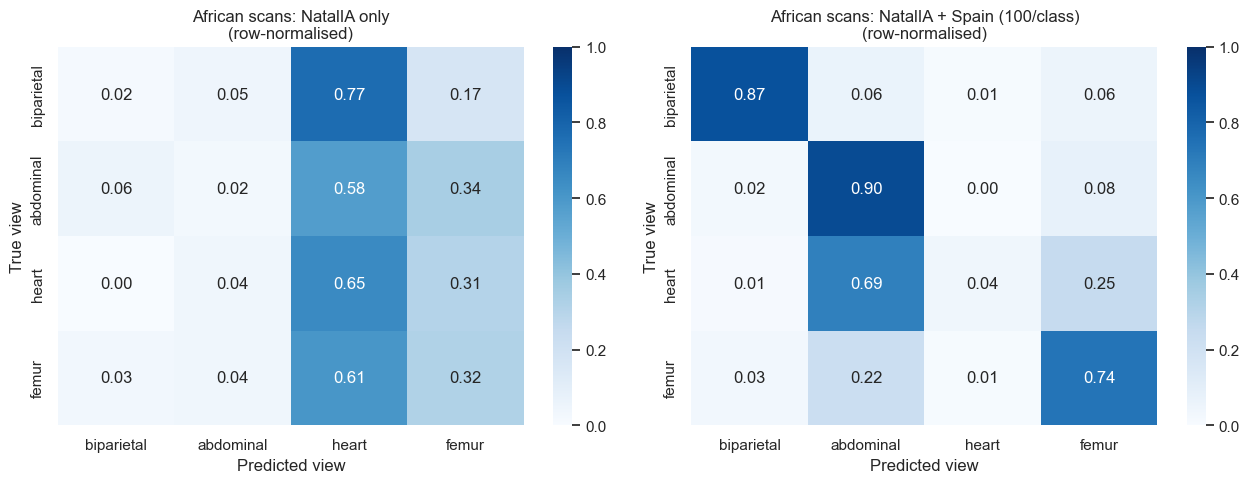

In [93]:
if B_PRED:
    pat_idx = list(africa.groupby("patient").indices.values())
    def boot_pat(stat, n=N_BOOT):
        rng = np.random.default_rng(SEED)
        vals = [stat(np.concatenate([pat_idx[j] for j in rng.integers(0, len(pat_idx), len(pat_idx))]))
                for _ in range(n)]
        return np.nanpercentile(vals, [2.5, 97.5])
    view_f1 = lambda y, v: f1_score(y, v, labels=sorted(set(y)), average="macro", zero_division=0)

    rows = []
    for name, r in B_PRED.items():
        lo, hi = boot_pat(lambda i: view_f1(Y_AFRICA[i], r["view"][i]))
        rows.append({"model": name, "images": len(africa), "detected as a key view": r["detected"].mean(),
                     "right view (accuracy)": (r["view"] == Y_AFRICA).mean(),
                     "right view (macro-F1)": view_f1(Y_AFRICA, r["view"]), "macro-F1 95% CI": f"{lo:.3f}–{hi:.3f}"})
    B_RESULTS = pd.DataFrame(rows)
    display(B_RESULTS.round(3))

    by_country = []
    for name, r in B_PRED.items():
        for ctry, ix in africa.groupby("country").indices.items():
            by_country.append({"model": name, "country": ctry, "images": len(ix),
                               "detected": r["detected"][ix].mean(),
                               "right view (accuracy)": (r["view"][ix] == Y_AFRICA[ix]).mean()})
    display(pd.DataFrame(by_country).pivot(index="country", columns="model",
                                           values=["detected", "right view (accuracy)"]).round(3))

    fig, axes = plt.subplots(1, len(B_PRED), figsize=(6.5 * len(B_PRED), 5), squeeze=False)
    for ax, (name, r) in zip(axes[0], B_PRED.items()):
        cmA = confusion_matrix(Y_AFRICA, r["view"], labels=EXT_IDS)
        sns.heatmap(cmA / cmA.sum(1, keepdims=True).clip(min=1), annot=True, fmt=".2f", cmap="Blues",
                    vmin=0, vmax=1, ax=ax, xticklabels=EXT_TARGETS, yticklabels=EXT_TARGETS)
        ax.set_title(f"African scans: {name}\n(row-normalised)"); ax.set_xlabel("Predicted view"); ax.set_ylabel("True view")
    plt.tight_layout(); plt.show()
else:
    print("African set not loaded: see 8.2.")

#### Experiment B: interpretation

TODO: how many real African scans the dummy-trained model recognises as key views, whether it names the right view, which countries and views are hardest, and whether the Spanish images help on real scans. Remember: these are single, well-framed images chosen by sonographers, not blind sweeps by midwives, and none are from Kenya. Treat this as the closest available evidence, not a Kenyan validation.

**Next step if results are weak:** fine-tune on a few African patients per country, as Sendra-Balcells et al. (2023) found 4–6 patients enough to recover performance.

## Part 7: Results Summary, Conclusions and Limitations

In this part we:

1. **Headline results (7.1):** collect the key number for each research question next to its target, and save the result tables.
2. **Conclusions (7.2):** to be written after running, one paragraph per research question.
3. **Limitations and next steps (7.3–7.4):** what the results can and cannot show, and what to do next.

**Why:** brings the answers to the four research questions together in one place.

### 7.1 Headline Results (filled automatically)

We gather the key result for each research question into one table next to its target, and save the result tables to `outputs/`.

**Step 1: Build the headline table**

Pulls the key result for each research question from earlier tables (with confidence intervals where available) and puts it next to its target.

In [94]:
f1_row = FRAME_SUMMARY.set_index("metric")
summary = pd.DataFrame([
    {"question": "RQ1 Plane macro-F1, strict (95% CI)",
     "result": f"{f1_row.loc['Plane macro-F1 (strict, all frames)', 'value']:.3f} "
               f"({f1_row.loc['Plane macro-F1 (strict, all frames)', '95% CI low']:.3f}–"
               f"{f1_row.loc['Plane macro-F1 (strict, all frames)', '95% CI high']:.3f})",
     "target": "≥ 0.70"},
    {"question": "RQ1 Plane-present average precision (chance)",
     "result": f"{f1_row.loc['Plane-present average precision', 'value']:.3f} ({(Y != NO_PLANE).mean():.3f})",
     "target": "well above chance"},
    {"question": "RQ2 Sweep-level hit@5", "result": f"{HIT_SUMMARY['hit@5']:.3f}", "target": "≥ 0.80"},
    {"question": "Selected configuration", "result": f"{BEST.name()} | sweep score: {FINAL['sweep_method']}",
     "target": "chosen on inner validation"},
    {"question": "RQ2 Sweep sensitivity / specificity",
     "result": f"{SWEEP_SUMMARY['sensitivity (plane sweeps passed)']:.2f} / {SWEEP_SUMMARY['specificity (empty sweeps flagged)']:.2f}",
     "target": "≥ 0.90 / as high as possible"},
    {"question": "RQ3 Worst held-out sweep type, plane recall",
     "result": f"{LOSO['plane_recall'].min():.3f} ({LOSO.loc[LOSO['plane_recall'].idxmin(), 'held_out_sweep_type']})",
     "target": "≥ 0.50"},
    {"question": "RQ4 Size / latency",
     "result": f"{DEPLOY_SUMMARY['tflite_MB']:.1f} MB / {DEPLOY_SUMMARY['cpu_ms_per_frame']:.0f} ms",
     "target": "< 20 MB / < 200 ms"},
])
ext_rows = []
if "A_RESULTS" in globals() and len(A_RESULTS) > 1:
    with_sp = A_RESULTS.loc[A_RESULTS["Spanish images per class"] == B_CAP].iloc[0]
    ext_rows.append({"question": f"RQ5 Plane macro-F1 on dummy sweeps: without / with Spanish images (+{B_CAP}/class)",
                     "result": f"{A_RESULTS.iloc[0]['plane macro-F1']:.3f} / {with_sp['plane macro-F1']:.3f} ({with_sp['95% CI']})",
                     "target": "higher with"})
if "B_RESULTS" in globals():
    for _, r in B_RESULTS.iterrows():
        ext_rows.append({"question": f"RQ5 African scans: detected / right view ({r['model']})",
                         "result": f"{r['detected as a key view']:.2f} / {r['right view (accuracy)']:.2f}",
                         "target": "as high as possible"})
summary = pd.concat([summary, pd.DataFrame(ext_rows)], ignore_index=True)
display(summary)

,question,result,target
0,"RQ1 Plane macro-F1, strict (95% CI)",0.388 (0.316–0.444),≥ 0.70
1,RQ1 Plane-present average precision (chance),0.352 (0.018),well above chance
2,RQ2 Sweep-level hit@5,0.771,≥ 0.80
3,Selected configuration,concat | logreg | C=0.03 | hard negatives | sw...,chosen on inner validation
4,RQ2 Sweep sensitivity / specificity,0.80 / 0.50,≥ 0.90 / as high as possible
5,"RQ3 Worst held-out sweep type, plane recall",0.178 (horizontal),≥ 0.50
6,RQ4 Size / latency,7.1 MB / 180 ms,< 20 MB / < 200 ms
7,RQ5 Plane macro-F1 on dummy sweeps: without / ...,0.388 / 0.399 (0.313–0.459),higher with
8,RQ5 African scans: detected / right view (Nata...,0.00 / 0.21,as high as possible
9,RQ5 African scans: detected / right view (Nata...,0.60 / 0.70,as high as possible


**Step 2: Save the results**

Saves the per-configuration results (`cv_results_by_config.csv`) and the headline table (`headline_results.csv`) to `outputs/`.

In [95]:
results.to_csv(OUT_DIR / "cv_results_by_config.csv", index=False)
summary.to_csv(OUT_DIR / "headline_results.csv", index=False)
print("Saved to", OUT_DIR)

Saved to c:\Users\OMokera\Desktop\Moringa\fetal_ultrasound_capstone\outputs


### 7.2 Conclusions

TODO (write after running, 1 short paragraph per RQ, quoting the numbers above with their confidence intervals):

- **RQ1:** how well planes are recognised, which planes are hardest (from 4.1–4.2), and how far above chance the plane-present detector is.
- **RQ2:** whether the sweep-level decision is usable: sensitivity, specificity and flag rate (4.4), and hit@5 (4.5).
- **RQ3:** which sweep type or fetal position is weakest (5.1–5.2).
- **RQ4:** size, latency and what the occlusion maps show (6.2–6.3).
- **What helped:** the ablation table (3.5): hard negatives, smoothing, backbone.

### 7.3 Limitations

1. **Phantom only.** One 23-week phantom, one probe (Clarius C3 HD3), one gestational age. Real tissue, maternal habitus, fetal movement and other gestational ages are absent, so results do not transfer directly to real pregnancies or African clinical settings.
2. **Few positives.** 346 plane frames (42–134 per plane) in 54 sweeps. Confidence intervals are wide by design; read them, not only the point estimates.
3. **Grouping by sweep.** Each volunteer recorded two sweeps; if they fall in different folds, operator style can leak slightly. `metadata.csv` has no volunteer ID to group on.
4. **Frozen backbone.** Features come from ImageNet weights without fine-tuning (fine-tuning gave little gain in v2). An ultrasound-pretrained backbone could do better.
5. **Labels.** Frames near a standard plane are labelled "no plane"; the lenient metric (ambiguous frames excluded) shows how much this penalises near-misses.
6. **Not a diagnostic tool.** No abnormality labels and no clinical validation.

### 7.4 Next Steps

Validate on real novice sweeps (for example a few ACOUSLIC-AI cases from Sierra Leone) to measure the phantom-to-real gap; try an ultrasound-pretrained backbone; seek AIMIX Kenya access for local validation.

**Citation:** González D., Barrientos J.P., Perez M., Fajardo J., Reyna F., Lara A. (2024). *NatalIA: PBF-US1 (Phantom Blind-sweeps for Fetal Ultrasound Scanning)*, v1.0.0. Zenodo. https://doi.org/10.5281/zenodo.14193949 (CC BY 4.0).